# [16.13] TreeSHAP from First Principles

> **Claim.** TreeSHAP can compute exact Shapley values for a precisely specified tree
  missing-feature game without enumerating every coalition; exact computation does not make the game
  itself uniquely correct.

## Core Question

How can we compute exact local Shapley values for a tree ensemble without enumerating every
coalition, and how can we tell whether a disagreement comes from the algorithm or from the
missing-feature game it was asked to explain?

In this lab you will build TreeSHAP rather than call an explainer. A five-node tree is small enough
to trace by hand, but it already contains the detail that breaks many plausible implementations: the
same feature can split twice on one path. You will then apply the same code to 18 fresh tree models
for concrete compressive strength and ask whether the explanations survive stronger controls.

The concrete study predicts strength in MPa from seven recipe quantities and curing age. It retains
all 1,030 public UCI rows and keeps identical seven-ingredient recipes in the same split. The frozen
protocol uses 758 training rows, 153 explanation rows and 119 audit rows. Rankings are fixed on the
explanation split before the audit labels are loaded.

## Learning objectives

By the end of the lab, you should be able to:

- state the coalition game behind path-dependent and empirical interventional TreeSHAP;
- implement tree routing with the same float32 boundary behavior as scikit-learn;
- derive exact Shapley values by coalition enumeration and by the TreeSHAP path recurrence;
- handle repeated features by unwinding their earlier path occurrence;
- exploit linearity across decision trees, random forests and boosted ensembles;
- distinguish a correct Shapley allocation from an efficient but order-dependent Saabas allocation;
- read prediction waterfalls, attribution heatmaps, runtime curves and deletion controls without
  turning them into causal claims.

Allow **4–6 hours**. Exercises 4–6 contain the algorithmic core; if time is short, do Exercises 1–3,
read the solutions to 4–5, and implement Exercise 6 yourself.

## Setup

Run this notebook from the repository environment. The full lab runs on CPU. The data loader
downloads the byte-pinned UCI CSV on first use, and every estimator uses one worker.


In [1]:
import itertools
import math
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

chapter = "chapter16_shapley_attribution_baselines"
section = "part13_treeshap"
root_dir = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

from part13_treeshap import treeshap_methods_tests as tests
from part13_treeshap.treeshap_data import background_order, load_split

FEATURE_NAMES = np.array([
    "Cement", "Blast-furnace slag", "Fly ash", "Water",
    "Superplasticizer", "Coarse aggregate", "Fine aggregate", "Age",
])
RUN_OUTPUT = os.environ.get("ARENA_TREESHAP_OUTPUT_DIRECTORY")
FIGURE_DIR = Path(
    os.environ.get("ARENA_TREESHAP_FIGURE_DIR", RUN_OUTPUT or section_dir / "figures")
)
SAVE_FIGURES = os.environ.get(
    "ARENA_TREESHAP_SAVE_FIGURES", "1" if RUN_OUTPUT else "0"
) == "1"


def show_figure(fig, stem):
    """Display a figure and optionally save the exact notebook rendering."""
    display(fig)
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


## 1️⃣ What game are we explaining?

A Shapley value starts with a set function $v(S)$: the value of knowing the features in coalition
$S$. For a prediction $f(x)$, writing “the SHAP value of feature $j$” is incomplete until we say how
$f$ is evaluated when some coordinates are missing.

We will use two games.

**Path-dependent game.** At a split on feature $j$, follow the query branch if $j\in S$. If $j\notin
S$, average both branches in proportion to their training cover. Recursing to the leaves defines
$v_{\mathrm{path}}(S;x)$. This is a property of the fitted tree structure and its stored covers. Two
functionally equivalent trees can therefore define different path games.

**Empirical interventional game.** Choose a complete background row $b$, form the hybrid $x_S
b_{\bar S}$, and average predictions without breaking the missing coordinates apart:

$$
v_{\mathrm{int}}(S;x)=\frac{1}{B}\sum_{b\in\mathcal B}f(x_S,b_{\bar S}).
$$

This game depends on the background. It preserves relationships among all missing coordinates
because they come from one intact donor, but a hybrid can still combine present and missing
coordinates in an unrealistic way. Neither game automatically equals $\mathbb E[f(X)\mid X_S=x_S]$,
and neither is a causal intervention on an ingredient.

The first visible control in the lab plots these three distinct questions side by side. Keep it in
mind whenever the word “exact” appears later.


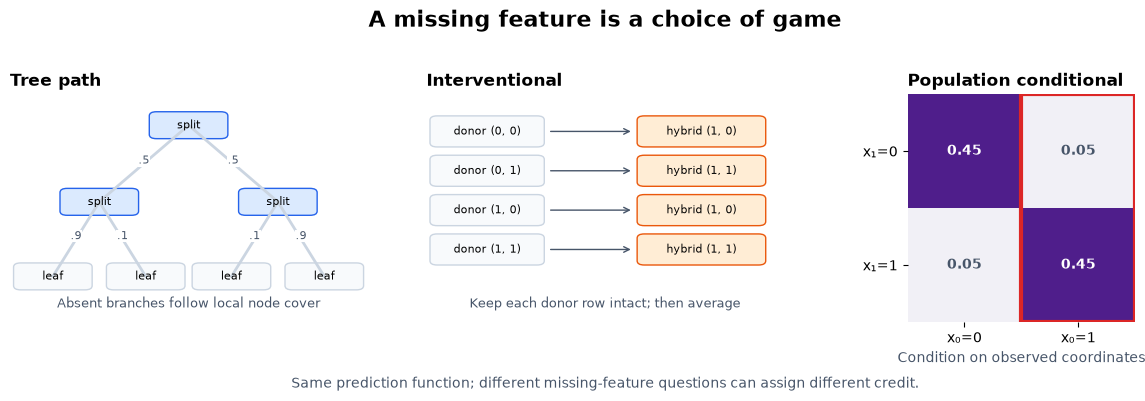

In [2]:
from part13_treeshap import treeshap_plots as plots

show_figure(plots.plot_missing_feature_games(), "01_missing_feature_games")


## 2️⃣ From a tree prediction to an exact coalition oracle

We represent one scalar-output tree with parallel arrays. Internal node `n` uses `feature[n]` and
`threshold[n]`; leaves have `left[n] == right[n] == -1`. `cover[n]` is the weighted number of
training examples reaching the node. This plain representation lets us inspect every operation that
an explainer performs.

### Exercise 1 — route a batch through one tree

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 15 minutes on this exercise.
> ```

Implement `tree_predict(tree, x)`. Route all unfinished rows together, replacing each row's current
node until every row reaches a leaf. First round `x` through `float32`, as scikit-learn does
internally, then store that rounded value in `float64` before comparing it with the tree's float64
threshold. The second cast prevents NumPy 1.26 from narrowing an array–scalar comparison back to
float32. Both details matter close to a learned split boundary.


In [3]:
def tree_predict(tree: dict, x: np.ndarray) -> np.ndarray:
    """Predict N rows with one scalar-output tree; match sklearn float32 routing."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    nodes = np.zeros(len(x), dtype=int)
    while True:
        active = np.flatnonzero(tree["left"][nodes] != -1)
        if not len(active):
            return tree["value"][nodes].copy()
        current = nodes[active]
        goes_left = x[active, tree["feature"][current]] <= tree["threshold"][current]
        nodes[active] = np.where(goes_left, tree["left"][current], tree["right"][current])



tests.test_tree_predict(tree_predict)


tree_predict: repeated thresholds and float32 boundary passed


<details><summary>Help - getting started</summary>

Keep an integer `nodes` array of length `N`. `tree["left"][nodes] != -1` tells you which rows are
still at internal nodes. For only those rows, compare the relevant input coordinate with the current
threshold and update their node indices with `np.where`.

</details>

<details><summary>Common bug - casting only to float32</summary>

Scikit-learn rounds query inputs to float32 but retains each learned threshold in float64. Comparing
a float32 NumPy array directly with a `np.float64` scalar can narrow the scalar in NumPy 1.26 and
move an equality-boundary query to the wrong branch. Round through float32, then widen the rounded
query to float64 before comparing it with the original threshold:

```python
x = np.asarray(x, dtype=np.float32).astype(np.float64)
```

The second cast does not recover discarded query precision; it preserves the threshold precision
during the comparison.

</details>

<details><summary>Expected output</summary>

```text
tree_predict: repeated thresholds and float32 boundary passed
```

The test includes a feature that is split twice and a query whose float64 value lies on the opposite
side of a threshold from its float32 representation.

</details>

<details><summary>Interpretation</summary>

This is a prediction check, not an attribution check. Exact contribution code cannot recover from
taking a different branch than the model it claims to explain.

</details>

<details><summary>Solution</summary>

```python
def tree_predict(tree: dict, x: np.ndarray) -> np.ndarray:
    """Predict N rows with one scalar-output tree; match sklearn float32 routing."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    nodes = np.zeros(len(x), dtype=int)
    while True:
        active = np.flatnonzero(tree["left"][nodes] != -1)
        if not len(active):
            return tree["value"][nodes].copy()
        current = nodes[active]
        goes_left = x[active, tree["feature"][current]] <= tree["threshold"][current]
        nodes[active] = np.where(goes_left, tree["left"][current], tree["right"][current])
```

</details>


### Exercise 2 — evaluate the path-dependent game

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 25 minutes on this exercise.
> ```

Implement `tree_path_game(tree, x, masks)`, returning one value per query and coalition. Recurse
from the root. At an internal node splitting feature $j$:

- if `masks[..., j]` is true, use the branch selected by the query;
- if it is false, average the left and right subtree values with weights `cover[left] / cover[node]`
  and `cover[right] / cover[node]`.

The same feature can occur more than once on a path. Coalition membership is still a single Boolean
decision: if feature $j$ is present, it controls every split on $j$.


In [4]:
def tree_path_game(tree: dict, x: np.ndarray, masks: np.ndarray) -> np.ndarray:
    """Return (N, K) coalition values using local training-cover branch weights."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    masks = np.asarray(masks, dtype=bool)

    def visit(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            return np.full((len(x), len(masks)), tree["value"][node])
        feature = tree["feature"][node]
        lvalue, rvalue = visit(left), visit(right)
        weight = tree["cover"][left] / tree["cover"][node]
        absent = weight * lvalue + (1 - weight) * rvalue
        present = np.where(
            (x[:, feature] <= tree["threshold"][node])[:, None], lvalue, rvalue
        )
        return np.where(masks[None, :, feature], present, absent)

    return visit(0)



tests.test_tree_path_game(tree_path_game)


tree_path_game: cover weighting and repeated-feature membership passed


<details><summary>Help - shapes</summary>

Let every recursive call return shape `(N,K)`. A leaf can use `np.full`. At an internal node,
`present` is chosen row by row, while `absent` is the cover-weighted average. Use `masks[None, :,
feature]` to select between them for every query and coalition.

</details>

<details><summary>Expected output</summary>

```text
tree_path_game: cover weighting and repeated-feature membership passed
```

For the correlated binary fixture at $x=(1,1)$, the two root orders produce games `[1.5, 2.8, 2.5,
3.0]` and `[1.5, 2.0, 2.9, 3.0]` in bit-mask order.

</details>

<details><summary>Interpretation</summary>

Both fixture trees compute $f(x)=x_0+2x_1$ on every binary input. Their missing-feature games differ
because training-cover averages are local to the tree path. That is the first warning against
reading path-dependent values as a structure-free population conditional.

</details>

<details><summary>Solution</summary>

```python
def tree_path_game(tree: dict, x: np.ndarray, masks: np.ndarray) -> np.ndarray:
    """Return (N, K) coalition values using local training-cover branch weights."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    masks = np.asarray(masks, dtype=bool)

    def visit(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            return np.full((len(x), len(masks)), tree["value"][node])
        feature = tree["feature"][node]
        lvalue, rvalue = visit(left), visit(right)
        weight = tree["cover"][left] / tree["cover"][node]
        absent = weight * lvalue + (1 - weight) * rvalue
        present = np.where(
            (x[:, feature] <= tree["threshold"][node])[:, None], lvalue, rvalue
        )
        return np.where(masks[None, :, feature], present, absent)

    return visit(0)
```

</details>


### Exercise 3 — contract an exhaustive game into Shapley values

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20 minutes on this exercise.
> ```

For $d$ features, the Shapley value of feature $j$ is

$$
\phi_j=\sum_{S\subseteq[d]\setminus\{j\}} \frac{|S|!(d-|S|-1)!}{d!}\left[v(S\cup\{j\})-v(S)\right].
$$

Since $\binom{d-1}{|S|}$ subsets have the same size, the coefficient is equivalently
$1/[d\binom{d-1}{|S|}]$. Implement `exact_shapley(values)`, where the final axis stores every
coalition and feature zero is the least-significant bit. Preserve any leading batch axes.


In [5]:
def exact_shapley(values: np.ndarray) -> np.ndarray:
    """Contract a (..., 2**D) game with the exact Shapley subset weights."""
    values = np.asarray(values, dtype=np.float64)
    d = int(math.log2(values.shape[-1]))
    if d < 1 or values.shape[-1] != 2**d:
        raise ValueError("The final axis must contain every subset of D >= 1 features.")
    phi = np.zeros((*values.shape[:-1], d))
    for feature in range(d):
        absent = [s for s in range(2**d) if not s & (1 << feature)]
        present = [s | (1 << feature) for s in absent]
        weights = np.array([1 / (d * math.comb(d - 1, s.bit_count())) for s in absent])
        phi[..., feature] = ((values[..., present] - values[..., absent]) * weights).sum(-1)
    return phi



tests.test_exact_shapley(exact_shapley)


exact_shapley: signed, interaction and all-ordering checks passed


<details><summary>Help - coalition indices</summary>

Infer `d` with `int(math.log2(values.shape[-1]))` and verify the axis really has length `2**d`. For
feature `j`, absent coalitions satisfy `not s & (1 << j)`; the matching present coalition is `s | (1
<< j)`.

</details>

<details><summary>Expected output</summary>

```text
exact_shapley: signed, interaction and all-ordering checks passed
```

The independent check averages marginal contributions over all $4!$ feature orderings for a random
four-player game.

</details>

<details><summary>Interpretation</summary>

This exponential implementation is our oracle. It is intentionally simple enough to audit and will
later test the dynamic program's full attribution vector. Checking only
$v([d])-v(\varnothing)=\sum_j\phi_j$ would miss many wrong allocations.

</details>

<details><summary>Solution</summary>

```python
def exact_shapley(values: np.ndarray) -> np.ndarray:
    """Contract a (..., 2**D) game with the exact Shapley subset weights."""
    values = np.asarray(values, dtype=np.float64)
    d = int(math.log2(values.shape[-1]))
    if d < 1 or values.shape[-1] != 2**d:
        raise ValueError("The final axis must contain every subset of D >= 1 features.")
    phi = np.zeros((*values.shape[:-1], d))
    for feature in range(d):
        absent = [s for s in range(2**d) if not s & (1 << feature)]
        present = [s | (1 << feature) for s in absent]
        weights = np.array([1 / (d * math.comb(d - 1, s.bit_count())) for s in absent])
        phi[..., feature] = ((values[..., present] - values[..., absent]) * weights).sum(-1)
    return phi
```

</details>


In [6]:
def coalition_masks(d: int) -> np.ndarray:
    """All subsets, with feature zero in the least-significant bit."""
    return np.array([[bool(s & (1 << j)) for j in range(d)] for s in range(2**d)])


tiny_masks = coalition_masks(2)
tiny_tree = tests.binary_tree()
tiny_x = np.array([[1.0, 1.0]])
tiny_game = tree_path_game(tiny_tree, tiny_x, tiny_masks)
tiny_phi = exact_shapley(tiny_game)
print("coalition values:", tiny_game[0].tolist())
print("exact SHAP:      ", tiny_phi[0].tolist())


coalition values: [1.5, 2.8000000000000003, 2.5, 3.0]
exact SHAP:       [0.9000000000000001, 0.5999999999999999]


You should see coalition values `[1.5, 2.8, 2.5, 3.0]` and contributions close to `[0.9, 0.6]`. The
empty value $1.5$ plus both contributions reconstructs the prediction $3.0$. The allocation is
already less obvious than the additive formula $x_0+2x_1$: correlated training covers and the root
order change what “missing” means.

## 3️⃣ Replace $2^d$ coalitions with a path recurrence

At a leaf, each unique split feature has two path fractions:

- $z_j$: the fraction of training cover that takes this branch when feature $j$ is absent;
- $o_j$: an indicator that the query takes this branch when feature $j$ is present.

For an interventional query–donor pair, $z_j$ is instead the donor's branch indicator. A leaf
contributes only for compatible present/absent choices. TreeSHAP groups all compatible coalitions by
cardinality and updates those weights as the recursion descends. This avoids materializing all $2^d$
masks.

For a path containing $k$ unique features, define the stored weight at cardinality $s$ as

$$
W_k(s)=\sum_{\substack{S\subseteq[k]\\|S|=s}}
\left(\prod_{i\in S}o_i\right)
\left(\prod_{i\notin S}z_i\right)
\frac{s!(k-s)!}{(k+1)!}.
$$

This is the total probability-weighted Shapley coefficient of every compatible size-$s$ coalition
on the current path. Our representation starts directly with $W_0(0)=1$; it omits the dummy root
entry used to align arrays in the paper's pseudocode.

### Exercise 4 — extend cardinality weights

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35 minutes on this exercise.
> ```

Suppose `weights[:, s]` is the accumulated Shapley path weight for choosing `s` present features
among the current unique path features. Adding one feature sends each old term to two places: absent
leaves the cardinality at `s`, while present moves it to `s+1`.

When a new feature is absent, a size-$s$ coalition stays at size $s$. The ratio of its new and old
factorial coefficients is

$$
\frac{s!(k+1-s)!/(k+2)!}{s!(k-s)!/(k+1)!}=\frac{k+1-s}{k+2}.
$$

When the feature is present, the coalition moves from size $s$ to $s+1$, and the corresponding ratio
is $(s+1)/(k+2)$. Implement `extend_path(weights, zero, one)` from these two cases. Do not mutate the
input.


In [7]:
def extend_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Add a unique feature to batched cardinality weights: (N, k+1) -> (N, k+2)."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.asarray(zero), np.asarray(one)
    k = weights.shape[1] - 1
    extended = np.zeros((len(weights), k + 2))
    for size in range(k + 1):
        extended[:, size] += zero * weights[:, size] * (k + 1 - size) / (k + 2)
        extended[:, size + 1] += one * weights[:, size] * (size + 1) / (k + 2)
    return extended



tests.test_extend_path(extend_path)


extend_path: all subsets and cardinality weights passed


<details><summary>Help - one old column makes two new terms</summary>

Let `k = weights.shape[1] - 1`. Allocate zeros with one extra column. For each `size` from zero
through `k`, add the absent term into column `size` and the present term into column `size + 1`.
`zero` and `one` are length-`N` arrays.

</details>

<details><summary>Expected output</summary>

```text
extend_path: all subsets and cardinality weights passed
```

The oracle independently enumerates every present/absent pattern for three heterogeneous batched
paths, including zero fractions.

</details>

<details><summary>Interpretation</summary>

The vector does not store one coalition; it stores the sum of compatible coalition weights at each
size. Features with the same coalition cardinality share the same Shapley coefficient, which is the
compression the dynamic program exploits.

</details>

<details><summary>Solution</summary>

```python
def extend_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Add a unique feature to batched cardinality weights: (N, k+1) -> (N, k+2)."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.asarray(zero), np.asarray(one)
    k = weights.shape[1] - 1
    extended = np.zeros((len(weights), k + 2))
    for size in range(k + 1):
        extended[:, size] += zero * weights[:, size] * (k + 1 - size) / (k + 2)
        extended[:, size + 1] += one * weights[:, size] * (size + 1) / (k + 2)
    return extended
```

</details>


### Exercise 5 — unwind an earlier feature

> ```yaml
> Difficulty: 🔴🔴🔴🔴🔴
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 45 minutes on this exercise.
> ```

A feature may split twice along one root-to-leaf path, but it remains one player in the cooperative
game. Before processing its later split, TreeSHAP removes the earlier extension, carries its
fractions forward, and then inserts the feature once with the combined branch fractions.

Write $W$ for the weights before one feature was added and $W'$ for the weights after it was added.
If the extended path contains $n$ features, the forward recurrence is

$$
W'_s=zW_s\frac{n-s}{n+1}+oW_{s-1}\frac{s}{n+1},
$$

with out-of-range terms equal to zero. Implement the inverse `unwind_path(weights, zero, one)`.
Work backward from the final cardinality. Where `one != 0`, recover the preceding value from the
present term; where `one == 0`, recover it from the absent term. Reject a dead path with both
fractions zero and do not mutate `weights`.


In [8]:
def unwind_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Remove one feature's extension, without mutating its input or dividing by zero."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.broadcast_arrays(np.asarray(zero), np.asarray(one))
    if np.any((zero == 0) & (one == 0)):
        raise ValueError("A dead path has no reversible extension; prune it first.")
    n = weights.shape[1] - 1
    if n < 1:
        raise ValueError("Cannot remove a feature from the empty path.")
    result = np.zeros((len(weights), n))
    next_one = weights[:, n].copy()
    nonzero = one != 0
    safe_one = np.where(nonzero, one, 1.0)
    safe_zero = np.where(nonzero, 1.0, zero)
    for size in range(n - 1, -1, -1):
        from_one = next_one * (n + 1) / ((size + 1) * safe_one)
        from_zero = weights[:, size] * (n + 1) / ((n - size) * safe_zero)
        result[:, size] = np.where(nonzero, from_one, from_zero)
        next_one = weights[:, size] - result[:, size] * zero * (n - size) / (n + 1)
    return result



tests.test_unwind_path(unwind_path)


unwind_path: arbitrary removal, zero fractions and no mutation passed


<details><summary>Help - invert the recurrence</summary>

Let `n = weights.shape[1] - 1`; the result has `n` columns. Preserve a `next_one` residual
initialized from the final column. Descend from `size=n-1` to zero. Use a safe denominator and
`np.where` so rows with `one == 0` take only the absent inversion. After recovering a column,
subtract its absent contribution from the current stored weight to update `next_one`.

</details>

<details><summary>Expected output</summary>

```text
unwind_path: arbitrary removal, zero fractions and no mutation passed
```

The test removes each of three different features, not only the most recently added one.

</details>

<details><summary>Interpretation</summary>

Repeated splits are a semantic constraint, not a small optimization detail. Treating two appearances
of feature $j$ as separate players changes the game and can assign the same input coordinate credit
twice.

</details>

<details><summary>Solution</summary>

```python
def unwind_path(weights: np.ndarray, zero: np.ndarray, one: np.ndarray) -> np.ndarray:
    """Remove one feature's extension, without mutating its input or dividing by zero."""
    weights = np.asarray(weights, dtype=np.float64)
    zero, one = np.broadcast_arrays(np.asarray(zero), np.asarray(one))
    if np.any((zero == 0) & (one == 0)):
        raise ValueError("A dead path has no reversible extension; prune it first.")
    n = weights.shape[1] - 1
    if n < 1:
        raise ValueError("Cannot remove a feature from the empty path.")
    result = np.zeros((len(weights), n))
    next_one = weights[:, n].copy()
    nonzero = one != 0
    safe_one = np.where(nonzero, one, 1.0)
    safe_zero = np.where(nonzero, 1.0, zero)
    for size in range(n - 1, -1, -1):
        from_one = next_one * (n + 1) / ((size + 1) * safe_one)
        from_zero = weights[:, size] * (n + 1) / ((n - size) * safe_zero)
        result[:, size] = np.where(nonzero, from_one, from_zero)
        next_one = weights[:, size] - result[:, size] * zero * (n - size) / (n + 1)
    return result
```

</details>


### Exercise 6 — implement recursive TreeSHAP

> ```yaml
> Difficulty: 🔴🔴🔴🔴🔴
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 60 minutes on this exercise.
> ```

Now assemble the recurrence in `tree_shap(tree, x, donor=None)`. With no donor, missing branches use
training-cover fractions and the function computes exact Shapley values for `tree_path_game`. With
one paired donor per query, a missing feature follows the donor branch; the result is exact for that
query–donor hybrid game.

Carry only live rows down each child. The path state contains unique feature IDs, their accumulated
zero and one fractions, and the cardinality weights. When the current split feature is already
present:

1. remove its earlier path extension;
2. remove its stored feature and fractions;
3. multiply the old fractions by the current branch fractions;
4. extend the path once with the combined fractions.

At a leaf, remove each feature in turn. The sum of the remaining path weights is the Shapley
coefficient accumulated over all positions at which that feature could enter. Multiply it by `(one -
zero)` and the leaf value.

More explicitly, after unwinding feature $j$ from a $k$-feature leaf path, that leaf contributes

$$
\text{leaf value}\times(o_j-z_j)\sum_{s=0}^{k-1}W^{(-j)}_{k-1}(s)
$$

to $\phi_j$. Summing this term over reachable leaves reconstructs the exact weighted marginal
contribution of $j$ without listing the coalitions individually.


In [9]:
def tree_shap(tree: dict, x: np.ndarray, donor: np.ndarray | None = None) -> np.ndarray:
    """Exact path-game SHAP, or paired-query/donor SHAP when donor has shape (N, D)."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    if donor is not None:
        donor = np.asarray(donor, dtype=np.float32).astype(np.float64)
        if donor.shape != x.shape:
            raise ValueError("Each query needs exactly one paired donor row.")
    phi = np.zeros(x.shape, dtype=np.float64)

    def visit(node, rows, features, zeros, ones, weights):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            for index, feature in enumerate(features):
                other_weights = unwind_path(weights, zeros[index], ones[index])
                phi[rows, feature] += (
                    other_weights.sum(1)
                    * (ones[index] - zeros[index])
                    * tree["value"][node]
                )
            return

        feature = tree["feature"][node]
        features, zeros, ones = list(features), list(zeros), list(ones)
        incoming_zero = incoming_one = np.ones(len(rows))
        if feature in features:
            index = features.index(feature)
            incoming_zero, incoming_one = zeros.pop(index), ones.pop(index)
            weights = unwind_path(weights, incoming_zero, incoming_one)
            features.pop(index)

        query_left = x[rows, feature] <= tree["threshold"][node]
        if donor is not None:
            donor_left = donor[rows, feature] <= tree["threshold"][node]
        for child, is_left in ((left, True), (right, False)):
            present = (query_left == is_left).astype(float)
            absent = (
                (donor_left == is_left).astype(float)
                if donor is not None
                else np.full(len(rows), tree["cover"][child] / tree["cover"][node])
            )
            zero, one = incoming_zero * absent, incoming_one * present
            keep = (zero != 0) | (one != 0)
            if not keep.any():
                continue
            visit(
                child,
                rows[keep],
                features + [feature],
                [z[keep] for z in zeros] + [zero[keep]],
                [o[keep] for o in ones] + [one[keep]],
                extend_path(weights[keep], zero[keep], one[keep]),
            )

    visit(0, np.arange(len(x)), [], [], [], np.ones((len(x), 1)))
    return phi



tests.test_tree_shap(tree_shap)


tree_shap: repeated features, dead donor paths, constants and dummies passed


<details><summary>Help - recursive state</summary>

Start with every row at node zero, empty feature/fraction lists, and weights `np.ones((N,1))`. For
each child, compute `present` from the query route and `absent` from either the donor route or the
child's share of parent cover. Keep rows where at least one fraction is nonzero, slice every batched
path array by that mask, then recurse.

</details>

<details><summary>Help - why prune dead rows?</summary>

If both fractions are zero, neither an absent nor a present coalition can reach that child for the
row. `unwind_path` intentionally rejects this non-invertible state, so discard it before recursing.

</details>

<details><summary>Expected output</summary>

```text
tree_shap: repeated features, dead donor paths, constants and dummies passed
```

For three tiny trees and 17 queries, the test compares every local contribution with exhaustive
enumeration under both path and paired-donor games. It also checks a repeated split, an unused dummy
coordinate, and a constant tree.

</details>

<details><summary>Interpretation</summary>

The result is algorithmically exact because it equals the exhaustive Shapley contraction for the
chosen game. That conclusion is stronger than additivity and narrower than saying the attribution is
the one true effect of a feature.

</details>

<details><summary>Solution</summary>

```python
def tree_shap(tree: dict, x: np.ndarray, donor: np.ndarray | None = None) -> np.ndarray:
    """Exact path-game SHAP, or paired-query/donor SHAP when donor has shape (N, D)."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    if donor is not None:
        donor = np.asarray(donor, dtype=np.float32).astype(np.float64)
        if donor.shape != x.shape:
            raise ValueError("Each query needs exactly one paired donor row.")
    phi = np.zeros(x.shape, dtype=np.float64)

    def visit(node, rows, features, zeros, ones, weights):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            for index, feature in enumerate(features):
                other_weights = unwind_path(weights, zeros[index], ones[index])
                phi[rows, feature] += (
                    other_weights.sum(1)
                    * (ones[index] - zeros[index])
                    * tree["value"][node]
                )
            return

        feature = tree["feature"][node]
        features, zeros, ones = list(features), list(zeros), list(ones)
        incoming_zero = incoming_one = np.ones(len(rows))
        if feature in features:
            index = features.index(feature)
            incoming_zero, incoming_one = zeros.pop(index), ones.pop(index)
            weights = unwind_path(weights, incoming_zero, incoming_one)
            features.pop(index)

        query_left = x[rows, feature] <= tree["threshold"][node]
        if donor is not None:
            donor_left = donor[rows, feature] <= tree["threshold"][node]
        for child, is_left in ((left, True), (right, False)):
            present = (query_left == is_left).astype(float)
            absent = (
                (donor_left == is_left).astype(float)
                if donor is not None
                else np.full(len(rows), tree["cover"][child] / tree["cover"][node])
            )
            zero, one = incoming_zero * absent, incoming_one * present
            keep = (zero != 0) | (one != 0)
            if not keep.any():
                continue
            visit(
                child,
                rows[keep],
                features + [feature],
                [z[keep] for z in zeros] + [zero[keep]],
                [o[keep] for o in ones] + [one[keep]],
                extend_path(weights[keep], zero[keep], one[keep]),
            )

    visit(0, np.arange(len(x)), [], [], [], np.ones((len(x), 1)))
    return phi
```

</details>


The builder inserts the readable diagnostic source in short, coherent cells. We will execute its
aggregator after all nine taught methods exist, so every diagnostic resolves to your current
notebook definitions.


In [10]:
import itertools

import math

import time

import numpy as np

def _method(methods, name):
    """Resolve a taught method in both the package and AST-extracted notebook."""
    if methods is not None:
        return getattr(methods, name) if hasattr(methods, name) else methods[name]
    local = globals().get(name)
    if callable(local):
        return local
    return getattr(_DEFAULT_METHODS, name)

def _as_query(query):
    query = np.asarray(query, dtype=float)
    if query.shape != (2,) or not np.isin(query, [0.0, 1.0]).all():
        raise ValueError("The binary fixture query must contain exactly two zeros/ones.")
    return query


The tiny fixtures construct two trees for the same binary function and one tree where a feature
appears at two thresholds. They expose every node value and cover used by later diagnostics.


In [11]:
def _binary_additive_tree(order=(0, 1), joint=((9.0, 1.0), (1.0, 9.0))):
    """Build an exact tree for f(x)=x0+2*x1 with population node covers."""
    order = tuple(int(feature) for feature in order)
    if sorted(order) != [0, 1]:
        raise ValueError("order must be a permutation of (0, 1).")
    joint = np.asarray(joint, dtype=float)
    if joint.shape != (2, 2) or np.any(joint <= 0):
        raise ValueError("joint must be a positive 2x2 table in (x0, x1) order.")
    examples = np.array(list(itertools.product([0, 1], repeat=2)))
    counts = joint.ravel()
    fields = {key: [] for key in ("left", "right", "feature", "threshold", "value", "cover")}

    def add(depth, keep):
        node = len(fields["left"])
        for key in fields:
            fields[key].append(-1)
        fields["cover"][node] = counts[keep].sum()
        fields["value"][node] = np.average(examples[keep] @ [1.0, 2.0], weights=counts[keep])
        fields["threshold"][node] = 0.5
        if depth < 2:
            feature = order[depth]
            fields["feature"][node] = feature
            fields["left"][node] = add(depth + 1, keep[examples[keep, feature] == 0])
            fields["right"][node] = add(depth + 1, keep[examples[keep, feature] == 1])
        return node

    add(0, np.arange(4))
    return {
        key: np.asarray(value, dtype=int if key in ("left", "right", "feature") else float)
        for key, value in fields.items()
    }

def _repeated_threshold_tree():
    """A hand-computable tree where x0 splits twice but remains one player."""
    return {
        "left": np.array([1, -1, 3, -1, -1]),
        "right": np.array([2, -1, 4, -1, -1]),
        "feature": np.array([0, -1, 0, -1, -1]),
        "threshold": np.array([1.0, 0.0, 2.0, 0.0, 0.0]),
        "value": np.array([20.0, 10.0, 80 / 3, 20.0, 30.0]),
        "cover": np.array([100.0, 40.0, 60.0, 20.0, 40.0]),
    }


The next group constructs population-conditional, empirical interventional and two path-dependent
games for the same binary prediction function. Direct enumeration here is a diagnostic oracle, not
an alternative implementation imported behind the exercises.


In [12]:
def _conditional_binary_game(query, joint):
    """Population-conditional game E[f(X) | X_S=query_S] by direct enumeration."""
    examples = np.array(list(itertools.product([0, 1], repeat=2)), dtype=float)
    probabilities = np.asarray(joint, dtype=float).ravel()
    probabilities /= probabilities.sum()
    targets = examples @ np.array([1.0, 2.0])
    masks = np.array(list(itertools.product([False, True], repeat=2)), dtype=bool)
    # Reorder lexicographic masks to the least-significant-feature convention.
    masks = masks[[0, 2, 1, 3]]
    values = []
    for mask in masks:
        matches = np.all(examples[:, mask] == query[mask], axis=1)
        values.append(np.average(targets[matches], weights=probabilities[matches]))
    return masks, np.asarray(values)

def _interventional_binary_game(query, joint):
    """Marginal/interventional game E[f(x_S, X_-S)] by direct enumeration."""
    examples = np.array(list(itertools.product([0, 1], repeat=2)), dtype=float)
    probabilities = np.asarray(joint, dtype=float).ravel()
    probabilities /= probabilities.sum()
    masks = np.array([[False, False], [True, False], [False, True], [True, True]])
    values = []
    for mask in masks:
        hybrids = np.where(mask, query, examples)
        values.append(np.average(hybrids @ np.array([1.0, 2.0]), weights=probabilities))
    return masks, np.asarray(values)


Now compare those definition-level games with each root ordering's cover-weighted path game and
Saabas allocation.


In [13]:
def correlated_games(query=(1.0, 1.0), joint=((0.45, 0.05), (0.05, 0.45)), methods=None):
    """Compare conditional, interventional and two cover-weighted path games.

    The two trees compute the same f(x)=x0+2*x1 on all binary inputs.  Only the
    root split changes, which makes any difference in their path attributions a
    property of the cover-weighted game rather than the predictive function.
    """
    query = _as_query(query)
    joint = np.asarray(joint, dtype=float)
    masks, conditional = _conditional_binary_game(query, joint)
    _, interventional = _interventional_binary_game(query, joint)
    trees = [_binary_additive_tree((0, 1), joint), _binary_additive_tree((1, 0), joint)]
    path_game = _method(methods, "tree_path_game")
    exact = _method(methods, "exact_shapley")
    saabas_fn = _method(methods, "saabas")
    games = np.vstack(
        [
            conditional,
            interventional,
            path_game(trees[0], query[None], masks)[0],
            path_game(trees[1], query[None], masks)[0],
        ]
    )
    shapley = exact(games)
    saabas_values = np.vstack([saabas_fn(tree, query[None])[1][0] for tree in trees])
    predictions = np.array(
        [_method(methods, "tree_predict")(tree, query[None])[0] for tree in trees]
    )
    return {
        "query": query,
        "joint": joint,
        "masks": masks,
        "game_names": [
            "Population conditional",
            "Interventional",
            "Path: x0 root",
            "Path: x1 root",
        ],
        "games": games,
        "shapley": shapley,
        "trees": trees,
        "saabas": saabas_values,
        "predictions": predictions,
        "empty_value": float(games[0, 0]),
    }


These checks enumerate path weights and evaluate a feature that appears at two thresholds. They are
the mechanism evidence behind the cardinality and repeated-feature figures.


In [14]:
def _enumerate_cardinality_weights(zeros, ones):
    """Definition-level subset enumeration for one unique-feature path."""
    zeros, ones = np.asarray(zeros, dtype=float), np.asarray(ones, dtype=float)
    count = len(zeros)
    answer = np.zeros(count + 1)
    for flags in itertools.product([False, True], repeat=count):
        size = sum(flags)
        product = math.prod(ones[j] if flag else zeros[j] for j, flag in enumerate(flags))
        answer[size] += (
            product
            * math.factorial(size)
            * math.factorial(count - size)
            / math.factorial(count + 1)
        )
    return answer

def path_cardinality_diagnostic(zeros=(0.2, 0.7, 0.5), ones=(1.0, 0.0, 1.0), methods=None):
    """Record each extend-path update and verify it against subset enumeration."""
    zeros, ones = np.asarray(zeros, dtype=float), np.asarray(ones, dtype=float)
    if zeros.shape != ones.shape or zeros.ndim != 1 or not len(zeros):
        raise ValueError(
            "zeros and ones must be non-empty one-dimensional arrays of equal length."
        )
    extend = _method(methods, "extend_path")
    weights = np.ones((1, 1))
    stages, exact_stages = [weights[0].copy()], [np.ones(1)]
    for index in range(len(zeros)):
        weights = extend(weights, zeros[[index]], ones[[index]])
        stages.append(weights[0].copy())
        exact_stages.append(
            _enumerate_cardinality_weights(zeros[: index + 1], ones[: index + 1])
        )
    return {
        "zeros": zeros,
        "ones": ones,
        "stages": stages,
        "enumerated_stages": exact_stages,
        "max_abs_error": float(
            max(np.max(np.abs(a - b)) for a, b in zip(stages, exact_stages))
        ),
    }


The repeated-feature evidence is separate because it tests a different invariant: two thresholds on
one coordinate still define one cooperative-game player, while an unused coordinate stays dummy.


In [15]:
def repeated_feature_diagnostic(methods=None):
    """Show that repeated x0 splits contract to one player and a dummy stays zero."""
    tree = _repeated_threshold_tree()
    query = np.array([[0.0, 99.0], [1.5, -7.0], [3.0, 4.0]])
    masks = _method(methods, "coalition_masks")(2)
    games = _method(methods, "tree_path_game")(tree, query, masks)
    phi = _method(methods, "tree_shap")(tree, query)
    base, saabas_values = _method(methods, "saabas")(tree, query)
    predictions = _method(methods, "tree_predict")(tree, query)
    return {
        "tree": tree,
        "query": query,
        "masks": masks,
        "games": games,
        "base": base,
        "phi": phi,
        "saabas": saabas_values,
        "prediction": predictions,
        "dummy_max_abs": float(np.max(np.abs(phi[:, 1]))),
        "additivity_max_abs_error": float(np.max(np.abs(base + phi.sum(1) - predictions))),
    }


Runtime needs its own fixed tree generator and timing harness. The generator supplies all dimensions
declared by the frozen sweep, including unused dummy features, so no dimension is removed after
seeing the timings.


In [16]:
def build_balanced_tree(depth, n_features=None, seed=161390):
    """Build the frozen balanced binary timing tree with one feature per level."""
    depth = int(depth)
    n_features = depth if n_features is None else int(n_features)
    if depth < 1 or n_features < depth:
        raise ValueError("depth must be positive and n_features must supply every tree level.")
    node_count = 2 ** (depth + 1) - 1
    leaf_start = 2**depth - 1
    left = np.full(node_count, -1, dtype=int)
    right = np.full(node_count, -1, dtype=int)
    feature = np.full(node_count, -1, dtype=int)
    threshold = np.zeros(node_count, dtype=float)
    value = np.zeros(node_count, dtype=float)
    cover = np.ones(node_count, dtype=float)
    for node in range(leaf_start):
        level = int(math.floor(math.log2(node + 1)))
        left[node], right[node], feature[node] = 2 * node + 1, 2 * node + 2, level
        threshold[node] = 0.5
    value[leaf_start:] = np.random.default_rng(seed).normal(loc=10.0, scale=3.0, size=2**depth)
    for node in range(leaf_start - 1, -1, -1):
        cover[node] = cover[left[node]] + cover[right[node]]
        value[node] = (
            cover[left[node]] * value[left[node]] + cover[right[node]] * value[right[node]]
        ) / cover[node]
    return {
        "left": left,
        "right": right,
        "feature": feature,
        "threshold": threshold,
        "value": value,
        "cover": cover,
        "n_features": np.array(n_features, dtype=int),
    }

def _fixed_queries(n_features):
    """Eight deterministic binary queries, with a visible 0..7 bit pattern."""
    integers = np.arange(8, dtype=int)
    return np.array(
        [
            [(number >> (feature % 3)) & 1 for feature in range(n_features)]
            for number in integers
        ],
        dtype=float,
    )


The benchmark retains three measurements per point and verifies the full dynamic-programming vector
against enumeration before recording any time.


In [17]:
def _benchmark_axis(specifications, methods, repeats):
    masks_fn = _method(methods, "coalition_masks")
    game_fn = _method(methods, "tree_path_game")
    exact_fn = _method(methods, "exact_shapley")
    dp_fn = _method(methods, "tree_shap")
    exact_times, dp_times, errors = [], [], []
    for depth, supplied_features in specifications:
        tree = build_balanced_tree(depth, supplied_features, seed=161390)
        query = _fixed_queries(supplied_features)
        masks = masks_fn(supplied_features)
        expected = exact_fn(game_fn(tree, query, masks))
        actual = dp_fn(tree, query)
        errors.append(float(np.max(np.abs(expected - actual))))
        current_exact, current_dp = [], []
        for _ in range(repeats):
            started = time.perf_counter()
            exact_fn(game_fn(tree, query, masks))
            current_exact.append(time.perf_counter() - started)
            started = time.perf_counter()
            dp_fn(tree, query)
            current_dp.append(time.perf_counter() - started)
        exact_times.append(current_exact)
        dp_times.append(current_dp)
    exact_times, dp_times = np.asarray(exact_times), np.asarray(dp_times)
    return {
        "exhaustive_seconds": exact_times,
        "dynamic_programming_seconds": dp_times,
        "exhaustive_median_seconds": np.median(exact_times, axis=1),
        "dynamic_programming_median_seconds": np.median(dp_times, axis=1),
        "max_abs_error": np.asarray(errors),
        "queries_per_timing": np.array(8, dtype=int),
        "repeats": np.array(repeats, dtype=int),
    }

def benchmark_runtime(methods=None, repeats=3):
    """Run both frozen timing sweeps and retain every wall-clock measurement."""
    repeats = int(repeats)
    if repeats != 3:
        raise ValueError("The frozen protocol requires exactly three timing repetitions.")
    dummy_features = np.array([3, 6, 9, 12, 15], dtype=int)
    depths = np.arange(2, 9, dtype=int)
    dummy = _benchmark_axis([(3, int(count)) for count in dummy_features], methods, repeats)
    depth = _benchmark_axis([(int(value), int(value)) for value in depths], methods, repeats)
    dummy["supplied_features"] = dummy_features
    dummy["tree_depth"] = np.array(3, dtype=int)
    depth["tree_depth"] = depths
    depth["supplied_features"] = depths.copy()
    return {"dummy_features": dummy, "depth": depth}


The editable play recomputes its tree, game and contributions from the chosen query, covers and root
feature. The aggregator stores deterministic mechanism evidence separately from wall-clock
measurements.


In [18]:
def tiny_tree_play(
    query=(1.0, 1.0),
    joint=((9.0, 1.0), (1.0, 9.0)),
    root_feature=0,
    methods=None,
):
    """Editable tiny-tree play: change the query, root feature, or four covers."""
    query = _as_query(query)
    root_feature = int(root_feature)
    if root_feature not in (0, 1):
        raise ValueError("root_feature must be 0 or 1.")
    tree = _binary_additive_tree((root_feature, 1 - root_feature), joint)
    masks = _method(methods, "coalition_masks")(2)
    game = _method(methods, "tree_path_game")(tree, query[None], masks)[0]
    phi = _method(methods, "tree_shap")(tree, query[None])[0]
    base, saabas_values = _method(methods, "saabas")(tree, query[None])
    prediction = _method(methods, "tree_predict")(tree, query[None])[0]
    return {
        "query": query,
        "joint": np.asarray(joint, dtype=float),
        "root_feature": np.array(root_feature, dtype=int),
        "tree": tree,
        "masks": masks,
        "game": game,
        "base": np.array(base[0]),
        "phi": phi,
        "saabas": saabas_values[0],
        "prediction": np.array(prediction),
    }


In [19]:
def run_diagnostics(methods=None, include_timing=True):
    """Return exact mechanism evidence and a separately persisted timing branch."""
    mechanism = {
        "correlated": correlated_games(methods=methods),
        "cardinality": path_cardinality_diagnostic(methods=methods),
        "repeated_feature": repeated_feature_diagnostic(methods=methods),
        "tiny_play": tiny_tree_play(methods=methods),
    }
    timing = benchmark_runtime(methods=methods) if include_timing else {}
    if timing:
        mechanism["runtime_parity"] = {
            axis: {
                "coordinate": (
                    values["supplied_features"]
                    if axis == "dummy_features"
                    else values["tree_depth"]
                ),
                "max_abs_error": values["max_abs_error"],
            }
            for axis, values in timing.items()
        }
        mechanism["runtime_parity"]["dummy_feature_max_abs"] = np.array(
            np.max(timing["dummy_features"]["max_abs_error"])
        )
        mechanism["runtime_parity"]["depth_max_abs"] = np.array(
            np.max(timing["depth"]["max_abs_error"])
        )
        timing = {
            axis: {key: value for key, value in values.items() if key != "max_abs_error"}
            for axis, values in timing.items()
        }
    return {"mechanism": mechanism, "timing": timing}


## 4️⃣ Ensembles and empirical interventional backgrounds

Tree ensembles are sums of trees plus an offset. Shapley values are linear in the game:

$$
\phi_j\!\left(c+\sum_t \alpha_t v_t\right)=\sum_t\alpha_t\phi_j(v_t).
$$

The offset and every tree's empty value contribute to the base prediction. Signed weights matter:
gradient boosting adds many learning-rate-scaled trees, and a general ensemble adapter should not
assume every coefficient is positive.

### Exercise 7 — combine trees and donor backgrounds

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 35 minutes on this exercise.
> ```

Implement `ensemble_shap(ensemble, x, background=None)`. In path mode, explain each tree once and
compute its empty value from the all-absent path game. In interventional mode, pair every query with
every intact background row, run your donor TreeSHAP, reshape, and average across donors. Return a
base value for each query and an `(N,D)` contribution matrix.


In [20]:
def ensemble_shap(
    ensemble: dict, x: np.ndarray, background: np.ndarray | None = None
) -> tuple[np.ndarray, np.ndarray]:
    """Use tree and donor linearity; return base (N,) and contributions (N, D)."""
    x = np.asarray(x)
    phi = np.zeros(x.shape, dtype=float)
    base = np.full(len(x), float(ensemble["offset"]))
    for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True):
        if background is None:
            contribution = tree_shap(tree, x)
            empty = tree_path_game(tree, x[:1], np.zeros((1, x.shape[1]), dtype=bool))[0, 0]
        else:
            background = np.asarray(background)
            if not len(background):
                raise ValueError("The empirical background cannot be empty.")
            queries = np.repeat(x, len(background), axis=0)
            donors = np.tile(background, (len(x), 1))
            contribution = tree_shap(tree, queries, donors).reshape(
                len(x), len(background), x.shape[1]
            ).mean(1)
            empty = tree_predict(tree, background).mean()
        phi += weight * contribution
        base += weight * empty
    return base, phi



tests.test_ensemble_shap(ensemble_shap)


ensemble_shap: signed tree weights, offsets and donor averaging passed


<details><summary>Help - donor batching</summary>

For `N` queries and `B` background rows, use `np.repeat(x, B, axis=0)` for queries and
`np.tile(background, (N,1))` for donors. Reshape contributions to `(N,B,D)` and average axis one.
The interventional base is the mean tree prediction over the background.

</details>

<details><summary>Expected output</summary>

```text
ensemble_shap: signed tree weights, offsets and donor averaging passed
```

The fixture combines two trees with weights `0.4` and `-0.2` plus offset `7.0`, and compares both
games with exhaustive enumeration.

</details>

<details><summary>Interpretation</summary>

Linearity lets us explain a forest or boosted model without constructing one giant tree. The
returned base belongs to the chosen game: changing the background changes both the base and
contributions while leaving the full prediction fixed.

</details>

<details><summary>Solution</summary>

```python
def ensemble_shap(
    ensemble: dict, x: np.ndarray, background: np.ndarray | None = None
) -> tuple[np.ndarray, np.ndarray]:
    """Use tree and donor linearity; return base (N,) and contributions (N, D)."""
    x = np.asarray(x)
    phi = np.zeros(x.shape, dtype=float)
    base = np.full(len(x), float(ensemble["offset"]))
    for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True):
        if background is None:
            contribution = tree_shap(tree, x)
            empty = tree_path_game(tree, x[:1], np.zeros((1, x.shape[1]), dtype=bool))[0, 0]
        else:
            background = np.asarray(background)
            if not len(background):
                raise ValueError("The empirical background cannot be empty.")
            queries = np.repeat(x, len(background), axis=0)
            donors = np.tile(background, (len(x), 1))
            contribution = tree_shap(tree, queries, donors).reshape(
                len(x), len(background), x.shape[1]
            ).mean(1)
            empty = tree_predict(tree, background).mean()
        phi += weight * contribution
        base += weight * empty
    return base, phi
```

</details>


### Exercise 8 — construct the empirical interventional oracle

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 25 minutes on this exercise.
> ```

Implement `interventional_game(predict, x, background, masks)`. For each query and coalition, copy
present coordinates from the query and all missing coordinates from one intact donor. Average
predictions over donors only after evaluating every hybrid.

Do not replace the background by its mean. For nonlinear trees, $f(\mathbb E[B])\neq\mathbb
E[f(B)]$. Do not draw a different donor independently for each missing feature either; that would
define another game.


In [21]:
def interventional_game(
    predict, x: np.ndarray, background: np.ndarray, masks: np.ndarray
) -> np.ndarray:
    """Average predictions of intact-donor hybrids, retaining all supplied donors."""
    if not len(background):
        raise ValueError("The empirical background cannot be empty.")
    result = np.empty((len(x), len(masks)))
    for start in range(0, len(x), 8):
        query = x[start : start + 8]
        hybrids = np.where(
            masks[None, :, None, :], query[:, None, None, :], background[None, None, :, :]
        )
        predictions = predict(hybrids.reshape(-1, x.shape[1]))
        result[start : start + len(query)] = predictions.reshape(
            len(query), len(masks), len(background)
        ).mean(2)
    return result



tests.test_interventional_game(interventional_game)


interventional_game: intact donors, nonlinear averaging and endpoints passed


<details><summary>Help - array layout</summary>

For a query batch, `np.where(masks[None,:,None,:], query[:,None,None,:], background[None,None,:,:])`
makes shape `(queries, coalitions, donors, features)`. Flatten only for prediction, then reshape and
average the donor axis. Small query batches keep peak memory bounded.

</details>

<details><summary>Expected output</summary>

```text
interventional_game: intact donors, nonlinear averaging and endpoints passed
```

The test uses a nonlinear interaction and explicitly rejects prediction at the mean donor.

</details>

<details><summary>Interpretation</summary>

This exponential routine is another oracle. In the real eight-feature study it evaluates all 256
coalitions for the first clean seed of each of three model families. It validates the full TreeSHAP
vector under exactly the background used by the lesson.

</details>

<details><summary>Solution</summary>

```python
def interventional_game(
    predict, x: np.ndarray, background: np.ndarray, masks: np.ndarray
) -> np.ndarray:
    """Average predictions of intact-donor hybrids, retaining all supplied donors."""
    if not len(background):
        raise ValueError("The empirical background cannot be empty.")
    result = np.empty((len(x), len(masks)))
    for start in range(0, len(x), 8):
        query = x[start : start + 8]
        hybrids = np.where(
            masks[None, :, None, :], query[:, None, None, :], background[None, None, :, :]
        )
        predictions = predict(hybrids.reshape(-1, x.shape[1]))
        result[start : start + len(query)] = predictions.reshape(
            len(query), len(masks), len(background)
        ).mean(2)
    return result
```

</details>


## 5️⃣ A fast allocation can conserve the total and still be wrong

Saabas attribution follows only the query's decision path. At each visited split it gives that
feature the change from the parent node expectation to the selected child expectation. These changes
telescope, so the result reconstructs the prediction. But the ordering is fixed by the tree, rather
than averaged across every feature ordering.

### Exercise 9 — implement the Saabas control

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 25 minutes on this exercise.
> ```

First compute every node's cover-weighted expected leaf value. Then route each query down one path
and assign `expected[child] - expected[parent]` to the split feature. Accumulate repeated
appearances of the same feature. Return the root expectation and contribution matrix.


In [22]:
def saabas(tree: dict, x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Assign each visited parent-to-child expectation change to its split feature."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    expected = np.zeros(len(tree["value"]))

    def expectation(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            expected[node] = tree["value"][node]
        else:
            expected[node] = (
                tree["cover"][left] * expectation(left)
                + tree["cover"][right] * expectation(right)
            ) / tree["cover"][node]
        return expected[node]

    expectation(0)
    phi = np.zeros(x.shape, dtype=float)
    for row, query in enumerate(x):
        node = 0
        while tree["left"][node] != -1:
            feature = tree["feature"][node]
            child = (
                tree["left"][node]
                if query[feature] <= tree["threshold"][node]
                else tree["right"][node]
            )
            phi[row, feature] += expected[child] - expected[node]
            node = child
    return np.full(len(x), expected[0]), phi



tests.test_saabas(saabas)


saabas: efficient allocation that differs from Shapley passed


<details><summary>Help - two traversals</summary>

Use a recursive post-order function to fill `expected`: leaves contribute their stored value and
internal nodes average their children by cover. Then use a separate loop to route each query from
root to leaf while accumulating expectation differences.

</details>

<details><summary>Expected output</summary>

```text
saabas: efficient allocation that differs from Shapley passed
```

On the same binary tree and query, Saabas gives `[1.3, 0.2]` while exact path SHAP gives `[0.9,
0.6]`. Both sum with the base `1.5` to prediction `3.0`.

</details>

<details><summary>Interpretation</summary>

Efficiency checks conservation, not fairness across feature orderings. A report that tests only
`base + phi.sum() == prediction` would accept this intentionally non-Shapley baseline.

</details>

<details><summary>Solution</summary>

```python
def saabas(tree: dict, x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Assign each visited parent-to-child expectation change to its split feature."""
    x = np.asarray(x, dtype=np.float32).astype(np.float64)
    expected = np.zeros(len(tree["value"]))

    def expectation(node):
        left, right = tree["left"][node], tree["right"][node]
        if left == -1:
            expected[node] = tree["value"][node]
        else:
            expected[node] = (
                tree["cover"][left] * expectation(left)
                + tree["cover"][right] * expectation(right)
            ) / tree["cover"][node]
        return expected[node]

    expectation(0)
    phi = np.zeros(x.shape, dtype=float)
    for row, query in enumerate(x):
        node = 0
        while tree["left"][node] != -1:
            feature = tree["feature"][node]
            child = (
                tree["left"][node]
                if query[feature] <= tree["threshold"][node]
                else tree["right"][node]
            )
            phi[row, feature] += expected[child] - expected[node]
            node = child
    return np.full(len(x), expected[0]), phi
```

</details>


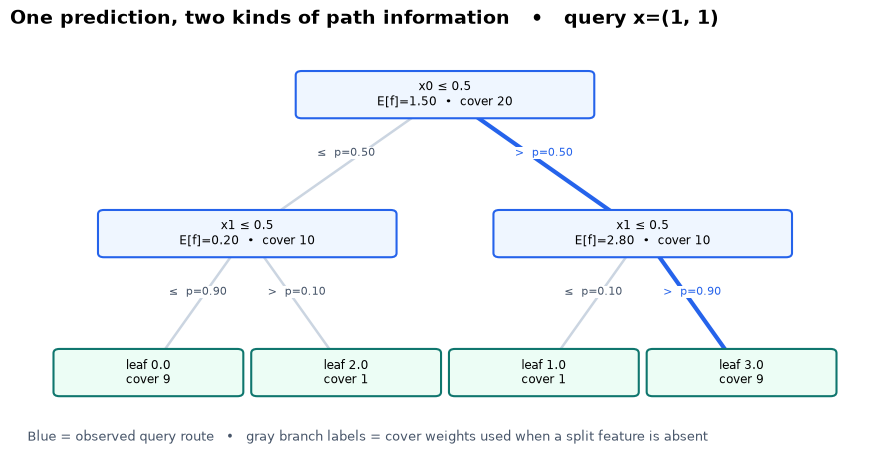

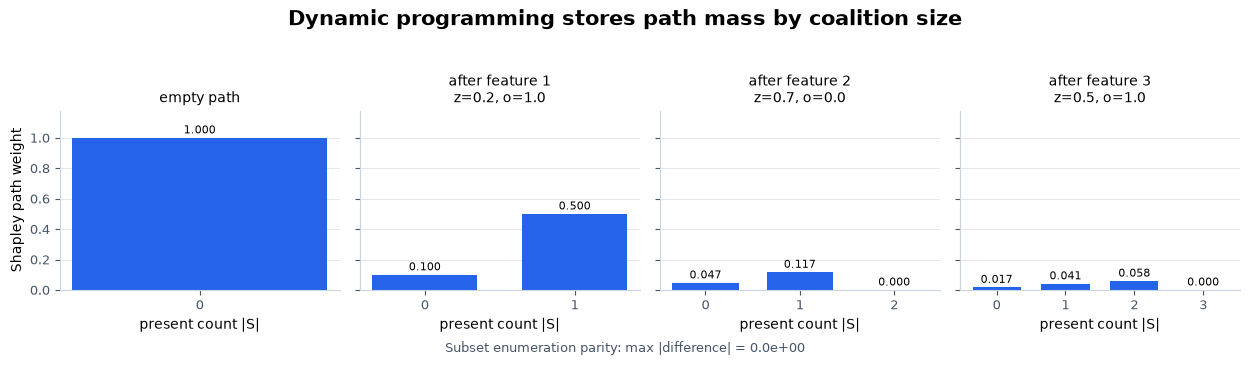

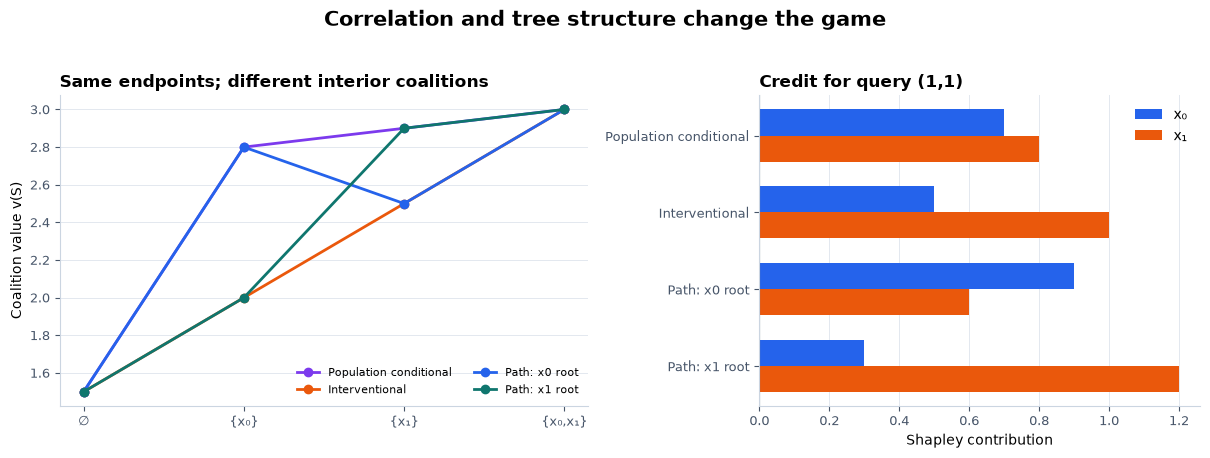

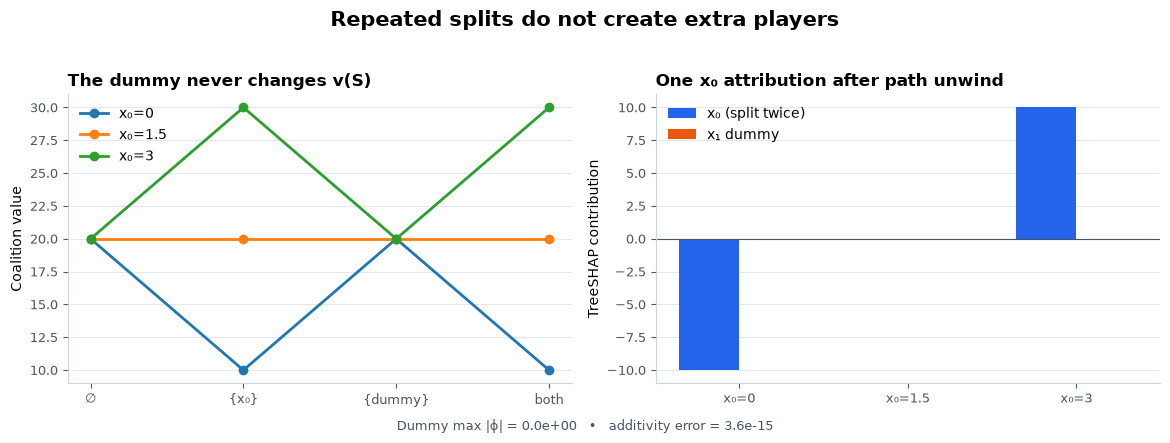

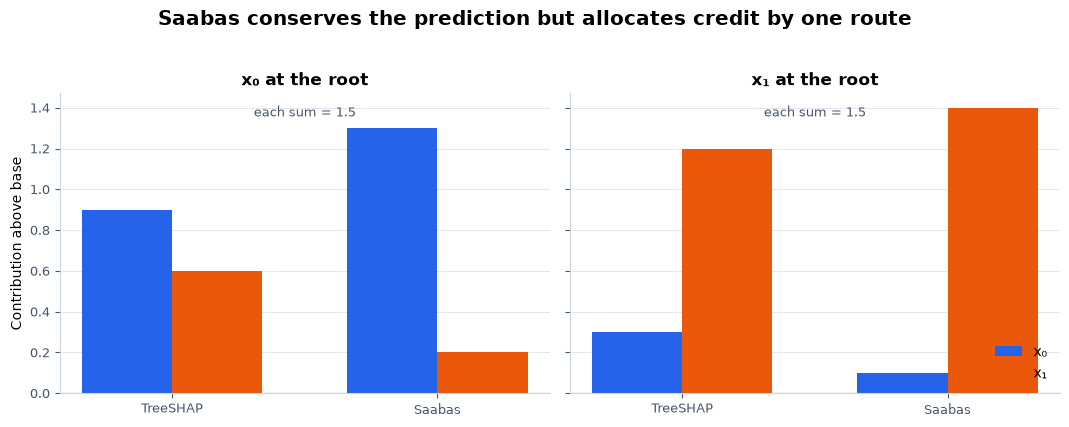

In [23]:
diagnostics = run_diagnostics(methods=globals(), include_timing=True)
show_figure(plots.plot_tiny_tree(diagnostics), "02_tiny_tree")
show_figure(plots.plot_cardinality_weights(diagnostics), "03_cardinality_weights")
show_figure(plots.plot_correlated_games(diagnostics), "04_correlated_games")
show_figure(plots.plot_repeated_feature(diagnostics), "05_repeated_feature")
show_figure(plots.plot_saabas_control(diagnostics), "06_saabas_control")


These figures expose the mechanism rather than treating the recurrence as a black box. The
cardinality panel compares dynamic weights with literal subset enumeration. The repeated-feature
panel shows why the second split must update the same player.

### Try It Yourself 1 — change a path, not just a number

Edit the query and node covers below. Before running, predict which leaf the query reaches and
whether increasing the cover of the *other* branch will raise or lower the empty-coalition value.
Then compare exhaustive and dynamic contributions.

This play is deliberately tiny: you can inspect every branch rather than trusting a polished plot.


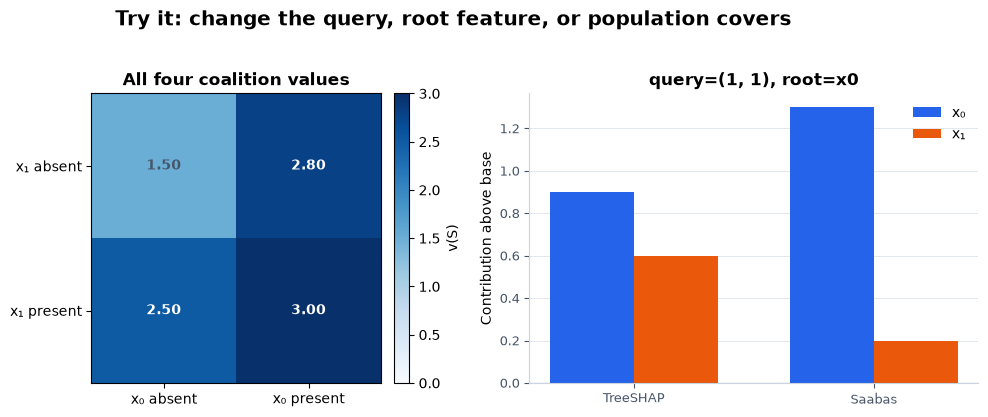

In [24]:
query = np.array([1.0, 1.0])
joint = np.array([[9.0, 1.0], [1.0, 9.0]])
root_feature = 0
tiny_play = tiny_tree_play(query=query, joint=joint, root_feature=root_feature)
show_figure(plots.plot_tiny_tree_play(tiny_play), "15_tiny_tree_play")


The correlated binary control separates four facts that are easy to blur together:

1. two trees can make identical full predictions;
2. their local cover-weighted path games can differ;
3. the empirical interventional game can differ from both path games;
4. the true conditional game for the specified population is yet another object.

The Saabas panel then gives a sharper negative control: conservation succeeds while Shapley parity
fails.

## 6️⃣ A frozen real-data study

The algorithm is ready; now we test whether it survives fitted models and held-out data. The
complete fitting and evaluation code below is inserted verbatim from `treeshap_study.py`. Read it
before running. It fits every predeclared family, seed and target control; computes rankings on the
explanation split; and only then evaluates deletion curves on the audit split.

The design was frozen before any native tree was fit. It includes:

- three model families × three seeds × clean or shuffled targets = **18 models**;
- path-dependent and 64-donor interventional explanations for every one of **272 held-out rows**;
- all 256 coalition values for both games on the first clean seed of each family;
- a training-target-mean prediction baseline and all nine shuffled-target fits;
- nested and independent background controls for the primary forest;
- 100 fixed random feature-deletion orders.

First adapt scikit-learn's estimators into the plain arrays used by your methods. Forest prediction
is an average of its trees; gradient boosting adds learning-rate-scaled trees to its constant
initializer. The adapter retains signed weights and verifies its predictions against scikit-learn
later.


In [25]:
import numpy as np

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def adapt_tree(estimator):
    raw = estimator.tree_
    return {
        "left": raw.children_left.copy(),
        "right": raw.children_right.copy(),
        "feature": raw.feature.copy(),
        "threshold": raw.threshold.copy(),
        "value": raw.value[:, 0, 0].copy(),
        "cover": raw.weighted_n_node_samples.copy(),
    }

def adapt_ensemble(model, family):
    if family == "tree":
        estimators, weights, offset = [model], np.ones(1), 0.0
    elif family == "forest":
        estimators = model.estimators_
        weights, offset = np.full(len(estimators), 1 / len(estimators)), 0.0
    elif family == "boost":
        estimators = model.estimators_.ravel()
        weights = np.full(len(estimators), model.learning_rate)
        offset = float(model.init_.constant_[0, 0])
    else:
        raise ValueError(f"Unknown family {family}.")
    return {
        "trees": [adapt_tree(tree) for tree in estimators],
        "weights": weights,
        "offset": offset,
    }

def ensemble_predict(ensemble, x):
    return float(ensemble["offset"]) + sum(
        weight * tree_predict(tree, x)
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )

def ensemble_path_game(ensemble, x, masks):
    return float(ensemble["offset"]) + sum(
        weight * tree_path_game(tree, x, masks)
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )

def ensemble_saabas(ensemble, x):
    return sum(
        weight * saabas(tree, x)[1]
        for tree, weight in zip(ensemble["trees"], ensemble["weights"], strict=True)
    )


The fitting cell is the entire frozen model grid. Read the loop order, seeds and shuffled-target
construction. There is no validation search, retry, early stopping or model selection hidden in a
runner.


In [26]:
def fit_models(train):
    models = {}
    for family in ("tree", "forest", "boost"):
        for seed_index in range(3):
            for target_kind in ("clean", "shuffled"):
                seed = 161310 + seed_index
                y = train["y"].copy()
                if target_kind == "shuffled":
                    y = y[np.random.default_rng(161320 + seed_index).permutation(len(y))]
                if family == "tree":
                    model = DecisionTreeRegressor(
                        max_depth=5, min_samples_leaf=8, random_state=seed
                    )
                elif family == "forest":
                    model = RandomForestRegressor(
                        n_estimators=32,
                        max_depth=5,
                        min_samples_leaf=8,
                        max_features=1.0,
                        bootstrap=True,
                        n_jobs=1,
                        random_state=seed,
                    )
                else:
                    model = GradientBoostingRegressor(
                        n_estimators=48,
                        learning_rate=0.05,
                        max_depth=3,
                        min_samples_leaf=8,
                        loss="squared_error",
                        subsample=1.0,
                        random_state=seed,
                    )
                model.fit(train["x"], y)
                key = f"{family}_{target_kind}_{seed_index}"
                models[key] = {
                    "sklearn": model,
                    "ensemble": adapt_ensemble(model, family),
                    "training_targets": y,
                    "parameters": model.get_params(),
                    "train_prediction": model.predict(train["x"]),
                }
    return {
        "models": models,
        "train_ids": train["ids"].copy(),
        "training_mean": float(train["y"].mean()),
    }


`explain_block` checks adapter prediction parity and additivity for all three allocations. For the
three first-seed clean families, it also constructs all 256 coalition values and requires your
dynamic program to match the exhaustive contraction. `prepare_study` fixes mean-absolute rankings
and the primary donor background using explanation rows only.


In [27]:
def explain_block(fitted, x, background):
    result = {}
    masks = coalition_masks(x.shape[1])
    exact_keys = {f"{family}_clean_0" for family in ("tree", "forest", "boost")}
    for key, item in fitted["models"].items():
        ensemble, model = item["ensemble"], item["sklearn"]
        prediction = ensemble_predict(ensemble, x)
        np.testing.assert_allclose(prediction, model.predict(x), atol=1e-10, rtol=1e-10)
        base_path, phi_path = ensemble_shap(ensemble, x)
        base_interventional, phi_interventional = ensemble_shap(ensemble, x, background)
        phi_saabas = ensemble_saabas(ensemble, x)
        for base, phi in (
            (base_path, phi_path),
            (base_interventional, phi_interventional),
            (base_path, phi_saabas),
        ):
            np.testing.assert_allclose(base + phi.sum(1), prediction, atol=1e-8, rtol=1e-8)
        result[key] = {
            "prediction": prediction,
            "base_path": base_path,
            "phi_path": phi_path,
            "base_interventional": base_interventional,
            "phi_interventional": phi_interventional,
            "phi_saabas": phi_saabas,
        }
        if key in exact_keys:
            game_path = ensemble_path_game(ensemble, x, masks)
            # Independent prediction route: exact hybrid games use the fitted sklearn model.
            game_interventional = interventional_game(model.predict, x, background, masks)
            for game, phi in ((game_path, phi_path), (game_interventional, phi_interventional)):
                np.testing.assert_allclose(exact_shapley(game), phi, atol=1e-8, rtol=1e-8)
            result[key].update(game_path=game_path, game_interventional=game_interventional)
    return result

def prepare_study(fitted, train, explain):
    order = background_order(train["ids"], 161360)
    background = train["x"][order[:64]]
    block = explain_block(fitted, explain["x"], background)
    rankings = {
        key: {
            name: np.argsort(-np.abs(item[f"phi_{name}"]).mean(0), kind="stable")
            for name in ("path", "interventional", "saabas")
        }
        for key, item in block.items()
    }
    return {
        "explanation": block,
        "rankings": rankings,
        "explain_ids": explain["ids"].copy(),
        "background_ids": train["ids"][order[:64]],
        "background": background,
        "audit_used_for_selection": False,
    }


The audit evaluator uses the already saved orderings, retains all random deletion orders and
alternate backgrounds, and computes performance for every model. Defining it does not load audit
rows; the explicit load remains below the persisted boundary.


In [28]:
def evaluate_study(fitted, prepared, train, explain, audit):
    block = explain_block(fitted, audit["x"], prepared["background"])
    rng = np.random.default_rng(161380)
    random_orders = np.array([rng.permutation(8) for _ in range(100)])
    deletion = {}
    for key, item in block.items():
        if "game_interventional" not in item:
            continue
        orders = np.vstack(
            [prepared["rankings"][key][name] for name in ("path", "interventional", "saabas")]
            + [random_orders]
        )
        masks_by_order = []
        for order in orders:
            mask, sequence = 255, [255]
            for feature in order:
                mask &= ~(1 << int(feature))
                sequence.append(mask)
            masks_by_order.append(sequence)
        predictions = item["game_interventional"][:, np.array(masks_by_order)]
        deletion[key] = {
            "orders": orders,
            "remaining_masks": np.array(masks_by_order),
            "mse": ((predictions - audit["y"][:, None, None]) ** 2).mean(0),
        }
    primary = fitted["models"]["forest_clean_0"]["ensemble"]
    all_x = np.vstack([explain["x"], audit["x"]])
    backgrounds = {}
    for size, seed in ((16, 161360), (128, 161360), (64, 161361), (64, 161362)):
        order = background_order(train["ids"], seed)[:size]
        base, phi = ensemble_shap(primary, all_x, train["x"][order])
        backgrounds[f"{size}_{seed}"] = {"ids": train["ids"][order], "base": base, "phi": phi}
    return {
        "audit": block,
        "audit_ids": audit["ids"].copy(),
        "audit_targets": audit["y"].copy(),
        "deletion": deletion,
        "backgrounds": backgrounds,
        "performance": {
            key: float(np.mean((item["prediction"] - audit["y"]) ** 2))
            for key, item in block.items()
        },
        "mean_baseline_mse": float(np.mean((fitted["training_mean"] - audit["y"]) ** 2)),
    }


The real-row play is kept separate from evaluation. It recomputes either missing-feature game for a
single selected audit row and model; its default arguments are the frozen canonical play.


In [29]:
def native_play(
    fitted, train, audit, model_key="forest_clean_0", row=0, size=64, game="interventional"
):
    query = audit["x"][[row]]
    indices = background_order(train["ids"], 161360)[:size]
    background = train["x"][indices] if game == "interventional" else None
    if game not in ("interventional", "path"):
        raise ValueError("Choose interventional or path.")
    ensemble = fitted["models"][model_key]["ensemble"]
    base, phi = ensemble_shap(ensemble, query, background)
    return {
        "query": query,
        "source_id": audit["ids"][[row]],
        "base": base,
        "phi": phi,
        "prediction": ensemble_predict(ensemble, query),
        "target": audit["y"][[row]],
    }


### Fit, prepare, and cross the audit boundary

The next two cells make the split boundary visible. The first loads only training and explanation
rows, fits all 18 models, fixes feature rankings, and persists that prepared state. The literal
audit load appears only in the following cell.


In [30]:
from part13_treeshap.run_native import (
    persist_completed,
    save_payload,
    write_before_audit,
    write_notebook_summary,
)

OUTPUT_ROOT = Path(
    os.environ.get("ARENA_TREESHAP_OUTPUT_DIRECTORY", section_dir / "notebook_output")
)
NATIVE_DIR = OUTPUT_ROOT / "native"
NATIVE_DIR.mkdir(parents=True, exist_ok=True)

train = load_split("train")
explain = load_split("explain")
fitted = fit_models(train)
prepared = prepare_study(fitted, train, explain)
save_payload(NATIVE_DIR, "fitted.pt", fitted)
save_payload(NATIVE_DIR, "prepared.pt", prepared)
write_before_audit(NATIVE_DIR, prepared)
print("Prepared rankings saved before audit load:", not prepared["audit_used_for_selection"])


Prepared rankings saved before audit load: True


Expected: `Prepared rankings saved before audit load: True`. This ordering does not make the audit
set magically unbiased for every later question. It means only that the predeclared rankings and
primary background were fixed without using audit rows or labels.


In [31]:
audit = load_split("audit")
evaluated = evaluate_study(fitted, prepared, train, explain, audit)
print("Models evaluated:", len(evaluated["performance"]))
print("Audit rows:", len(evaluated["audit_ids"]))


Models evaluated: 18
Audit rows: 119


Expected: 18 models and 119 audit rows. Before interpreting feature values, inspect the predictive
control. Shuffled-target models should fail on held-out recipes; if they do not, attribution plots
from the clean models are not the first thing to debug.


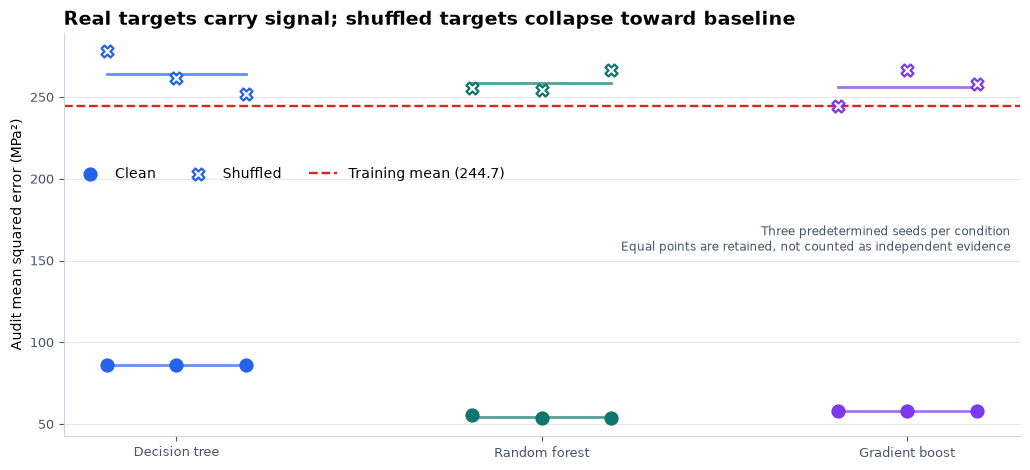

In [32]:
show_figure(plots.plot_performance(evaluated), "07_audit_performance")


On the frozen run, the training-mean baseline had audit MSE **244.68 MPa²**. Clean decision trees
scored **86.38**, clean forests **53.74–55.68**, and clean boosted ensembles **58.19**. The
shuffled-target controls scored **244.30–277.88**, failing to improve reliably on the constant
predictor. This is the required gate before interpreting their attributions.

The three clean decision-tree fits and three clean boosted fits make identical full predictions
here; these algorithms have no effective stochastic choice under the frozen settings and data. Their
repeated seeds are reproducibility checks, not three independent uncertainty estimates. The
bootstrapped forests do vary across seeds.


### Independent reference comparison — including a failure

Our exhaustive subset calculations are independent of the dynamic program but reuse our tree
adapter. The next check adds the installed SHAP 0.49.1 `TreeExplainer` implementation: raw
regression output, explicit `tree_path_dependent` or `interventional` mode, and the exact frozen
background.

It compares actual predictions, bases and every coordinate of every local vector for all 18 models
and all 272 held-out rows. The compiled interventional implementation uses float32 contribution
buffers, so its frozen tolerance is `atol=2e-5, rtol=2e-6`; the float64 exhaustive oracle uses
`atol=rtol=1e-8`. These comparisons are stronger than checking only additivity.

The frozen expectation that unmodified SHAP 0.49.1 would meet that tolerance was **falsified**. Its
compiled interventional adapter narrows tree thresholds to float32. One learned threshold,
`10.099999904632568`, becomes `10.100000381469727`; a query whose sklearn input is rounded to the
latter value then takes the opposite branch. In the primary-forest example, the raw reference misses
two explanation rows by about **0.4902 MPa**. We retain every affected model-row pair and its arrays
across the full 18-model comparison.

We also run a separately labeled compatibility reference. It replaces every compiled-explainer
threshold by the greatest float32 number no larger than the original threshold. For every
float32-representable query $q$ and finite threshold $t$,

$$q\le t\quad\Longleftrightarrow\quad q\le \lfloor t\rfloor_{32}.$$

This global transformation is applied to a separate copied explainer before any row is explained.
It does not post-process individual examples or attribution arrays. It leaves the fitted model,
student algorithm, selected rows and tolerance unchanged, then recomputes reference attributions;
affected rows are expected to change. Its strict agreement supports the diagnosis while the raw
failure remains part of the result.


Reference checks: {'row_identity': True, 'background_identity_all_64': True, 'prediction': True, 'path_compiled': True, 'interventional_unmodified': False, 'interventional_threshold_corrected': True, 'exhaustive_path': True, 'exhaustive_interventional': True, 'sklearn_models_unchanged': True}
Raw compiled parity passed: False
Threshold-compatible parity passed: True
Maximum absolute errors by check:
  prediction                   3.553e-14
  path_base                    1.421e-14
  path_phi                     2.842e-14
  interventional_raw_base      2.132e-14
  interventional_raw_phi       3.760e-01
  interventional_raw_prediction_residual 6.168e-01
  interventional_raw_nearest_threshold_additivity 3.142e-06
  interventional_corrected_base 2.132e-14
  interventional_corrected_phi 2.825e-06
  interventional_corrected_prediction_residual 3.142e-06
  exact_path_phi               2.842e-14
  exact_interventional_phi     1.456e-06
  exact_interventional_raw_phi 3.064e-01
  exact_raw_rounde

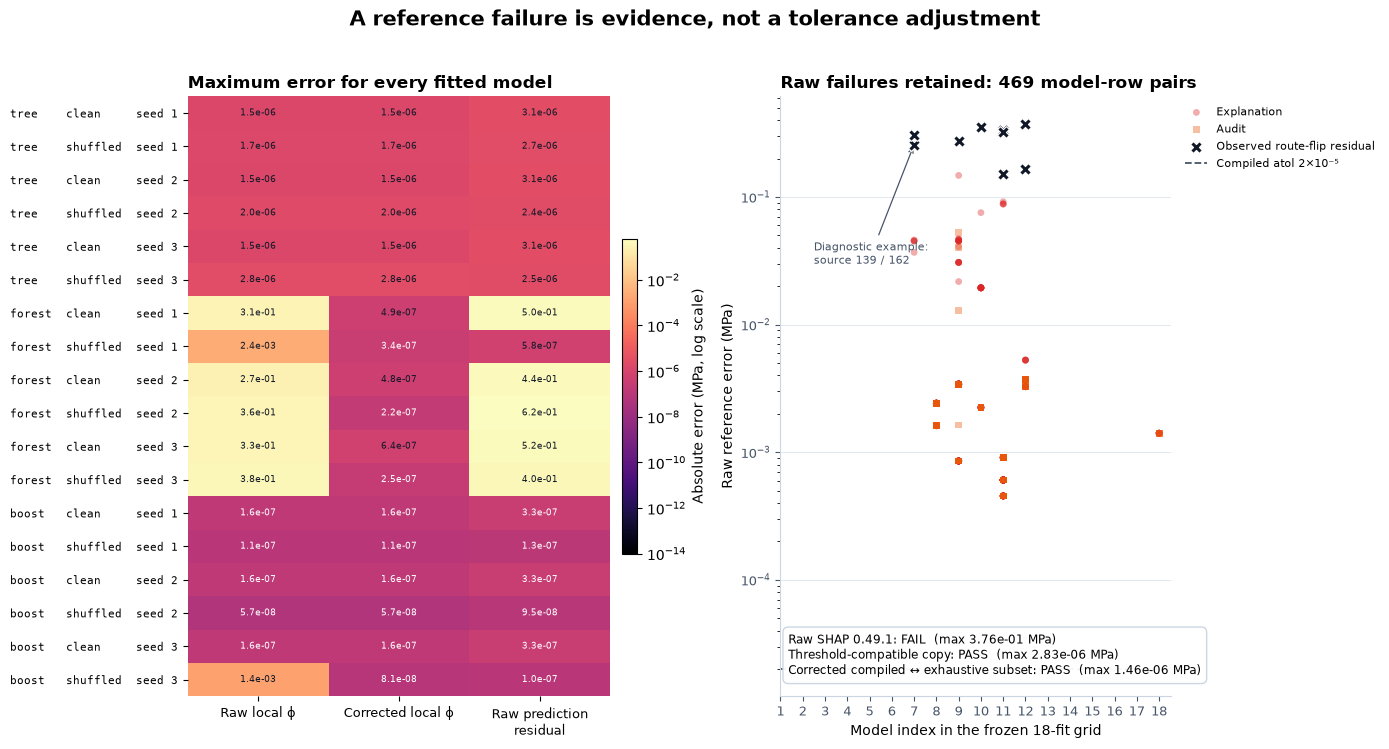

In [33]:
from part13_treeshap.treeshap_reference import check_reference

reference = check_reference(fitted, prepared, evaluated, explain, audit)
print("Reference checks:", reference["passes"])
print("Raw compiled parity passed:", reference["unmodified_interventional_passed"])
print(
    "Threshold-compatible parity passed:",
    reference["threshold_corrected_interventional_passed"],
)
print("Maximum absolute errors by check:")
for name, error in reference["max_errors"].items():
    print(f"  {name:28s} {error:.3e}")
show_figure(plots.plot_reference_parity(reference), "17_reference_parity")


<details><summary>Expected output and interpretation</summary>

The raw flag should be `False` and the threshold-compatible flag should be `True`. Across all 18
models, raw local-vector parity fails on 469 model-row pairs; raw base-plus-contribution sums fail on
18. The maximum raw local-coordinate error is `0.376032` MPa and the maximum raw reconstruction
error is `0.616826` MPa. Do not erase these results or increase the tolerance.

After the global threshold correction, the maximum local-coordinate error is `2.825e-6` MPa and the
maximum reconstruction error is `3.142e-6` MPa, within the frozen tolerance. On all 816 rows of the
three exact model-family checks, the compiled reference for the rounded-threshold game agrees with
exhaustive enumeration to `1.456e-6`. Separately, the student recurrence against the original
float64 exhaustive audit games reaches about `2.49e-14`. Together these results diagnose numerical
routing semantics rather than hiding the failed control.

</details>

<details><summary>Numerical boundary - inspect the counterexample</summary>

In NumPy 1.26, comparing a float32 array with a `np.float64` scalar can narrow the scalar to float32
for the ufunc. That is why the student router first rounds inputs through float32 and then widens
them back to float64. The first cast matches sklearn's input domain; the second preserves the
original float64 threshold during comparison.

The independent reference check records every adjusted threshold plus its adjacent float32 values
and verifies the partition equivalence above. See `reference_boundary_addendum.md` beside this
notebook for the full post-freeze account.

</details>


### Signature result — one prediction, then the whole held-out block

A waterfall answers a local accounting question: relative to the chosen base, which coordinates move
this recipe's prediction up or down? The heatmaps then show all explanation rows, sorted by the
primary forest's prediction and using a shared diverging scale. Look for structure that repeats
across rows, and for features whose sign or magnitude changes between games.

The path and interventional columns need not agree. Their disagreement is evidence that the
missing-feature definition matters, not evidence that one implementation is approximate.


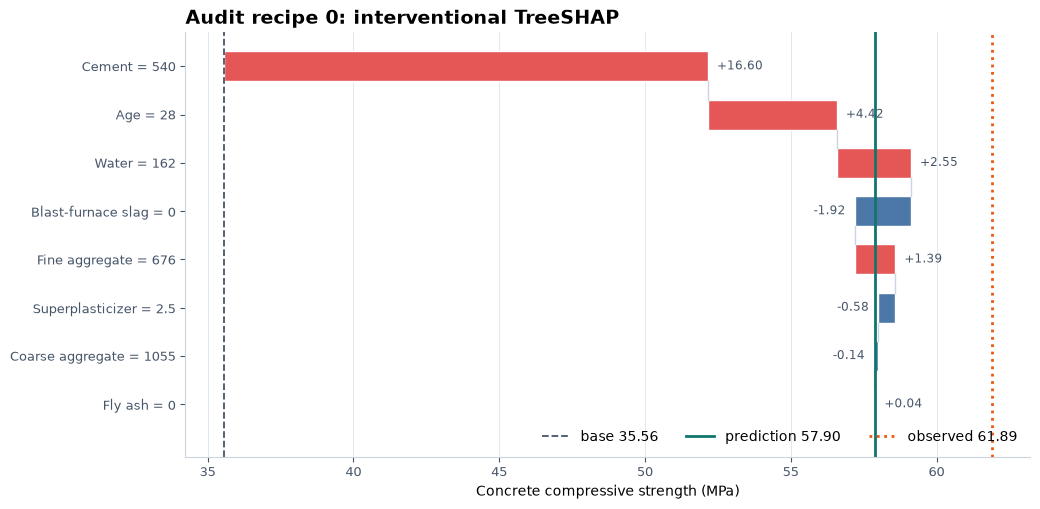

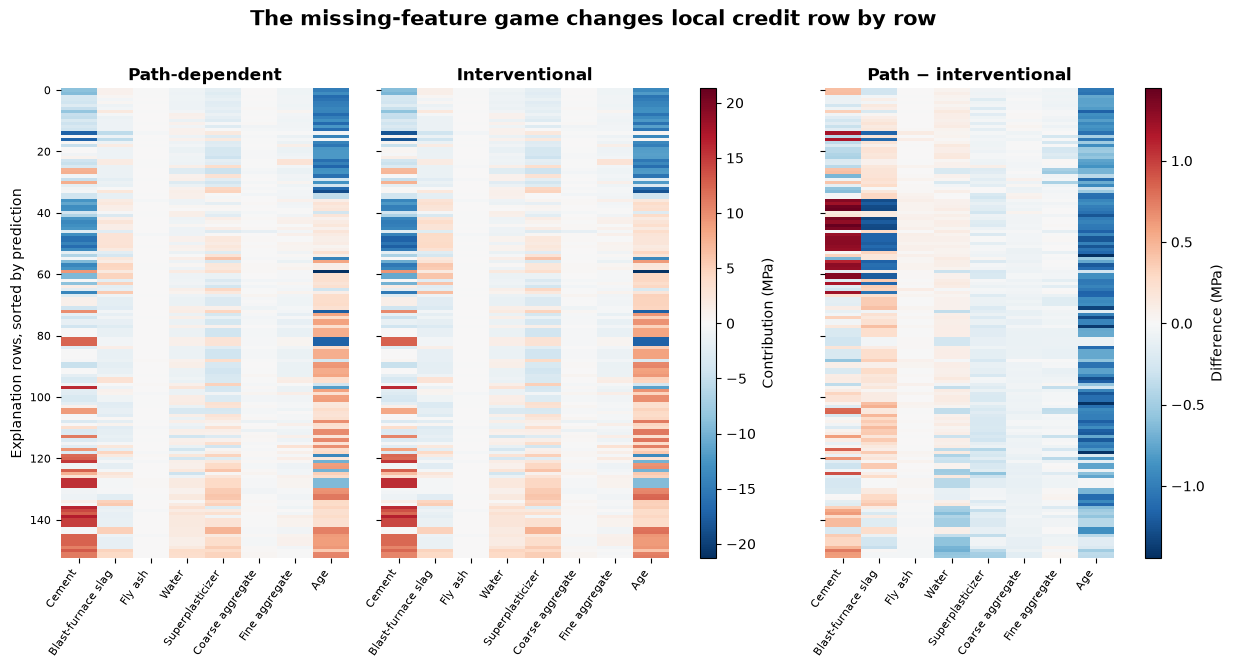

In [34]:
default_play = native_play(
    fitted, train, audit,
    model_key="forest_clean_0", row=0, size=64, game="interventional",
)
show_figure(
    plots.plot_waterfall(
        default_play,
        FEATURE_NAMES,
        title="Audit recipe 0: interventional TreeSHAP",
    ),
    "08_prediction_waterfall",
)
show_figure(
    plots.plot_attribution_heatmaps(
        prepared["explanation"]["forest_clean_0"],
        FEATURE_NAMES,
        row_labels=prepared["explain_ids"],
    ),
    "09_attribution_heatmaps",
)


For the frozen default, source row 1 has observed strength **61.89 MPa** and predicted strength
**57.90 MPa**. The interventional base is **35.56 MPa**. Cement contributes **+16.60 MPa** and age
**+4.42 MPa**; slag contributes **−1.92 MPa**, with the other five coordinates completing the
waterfall. The path-dependent base is **36.52 MPa**. The prediction stays fixed while the reference
and allocation change.


### Controls across fits, backgrounds and deletion orderings

The model-variation panel retains all three seeds and all shuffled fits. The background panel
changes only the empirical donor set for the primary forest: a nested 16/64/128 sequence and two
independent 64-row sets. A stable full prediction can coexist with moving bases and attributions
because the reference game changed.

For deletion, the explanation split supplies one feature ordering for path SHAP, interventional SHAP
and Saabas. On audit rows, features are then removed according to those fixed orders and predictions
are read from the exact interventional coalition game. The comparison includes every one of 100
random orderings.

Deletion is a diagnostic of this fitted model under synthetic missingness. It is not retraining on
smaller recipes, and it is not an instruction to physically remove an ingredient.

In the frozen result, alternate-background bases for the primary forest range from **34.01** to
**37.84 MPa**, compared with **35.56 MPa** for the primary 64-row background. Path SHAP,
interventional SHAP and Saabas happen to produce the same mean-absolute ranking for the clean forest
and boost, so their deletion curves overlap. The clean tree differs only at the three-feature prefix.
This negative result is informative: these curves do not establish that a Shapley ordering is more
useful than the cheaper Saabas ordering on this model and dataset.


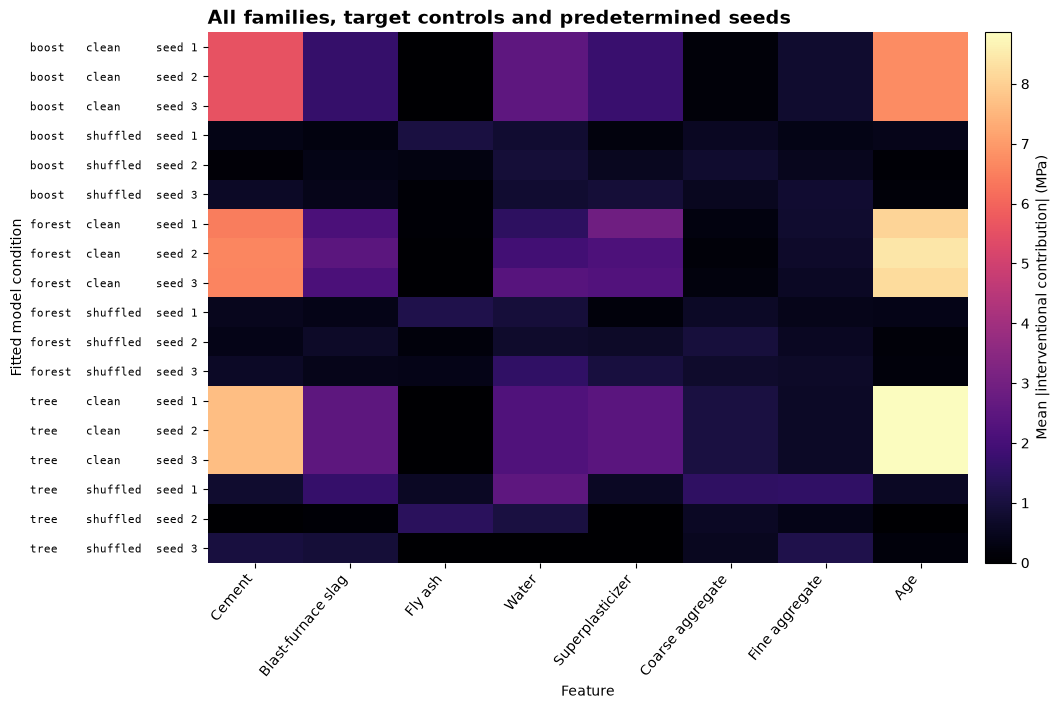

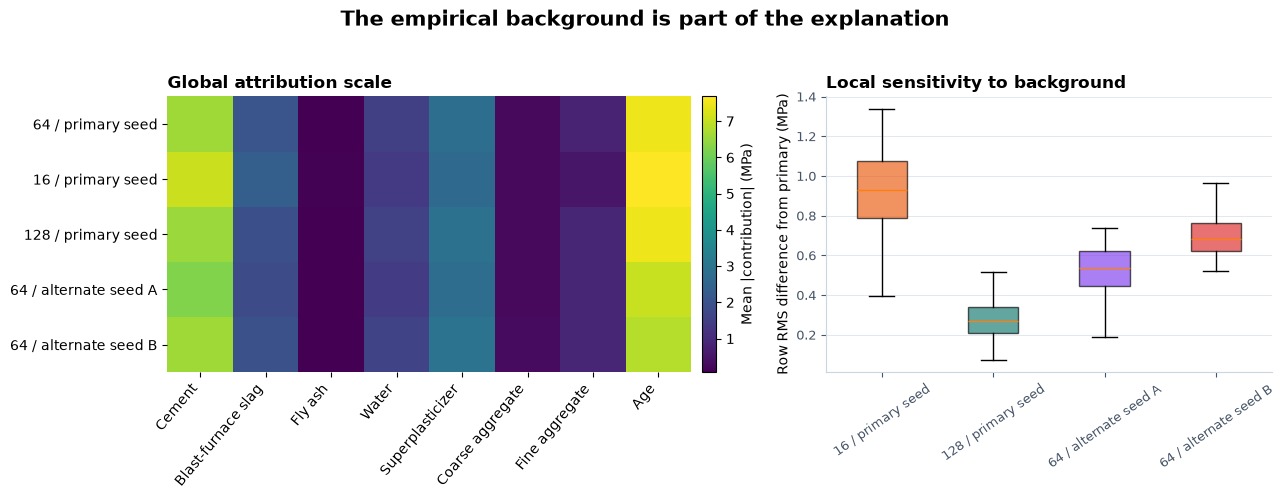

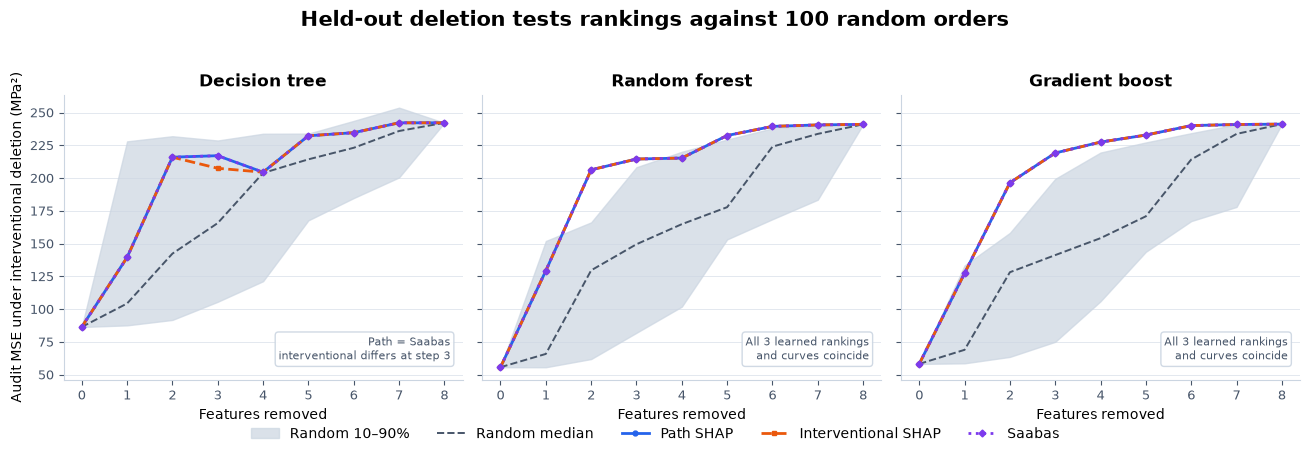

In [35]:
show_figure(
    plots.plot_model_variation(prepared["explanation"], FEATURE_NAMES),
    "10_model_seed_variation",
)
show_figure(
    plots.plot_background_sensitivity(prepared, evaluated, FEATURE_NAMES),
    "11_background_sensitivity",
)
show_figure(
    plots.plot_deletion_curves(evaluated),
    "12_deletion_curves",
)


### Runtime: the exponential axis and the path-depth axis

The first timing control holds a depth-three tree fixed while supplying 3, 6, 9, 12 and 15 features.
Extra features are explicit dummies. Exhaustive enumeration still visits their coalitions unless it
removes dummies first; the path recurrence follows the same shallow tree. The second timing control
increases tree depth from two through eight with one feature per level.

Wall-clock curves describe this machine and implementation. In the frozen depth-2…8 sweep, this
readable Python dynamic program is slower than the vectorized exhaustive oracle at every point; at
depth eight it takes roughly 100 ms for eight queries, versus roughly 2 ms for enumeration. The
polynomial algorithm has larger Python constant factors at these small dimensions. On the fixed
depth-three dummy sweep, it wins only once enumeration is forced to pay for 12 and 15 supplied
features. The diagnostic stores all three timings and plots their medians. Algorithmic scaling does
not promise that this teaching implementation is faster on every small tree.


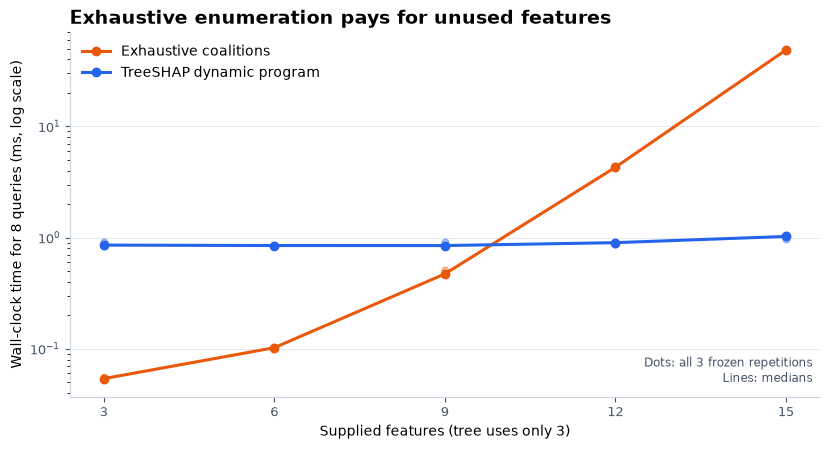

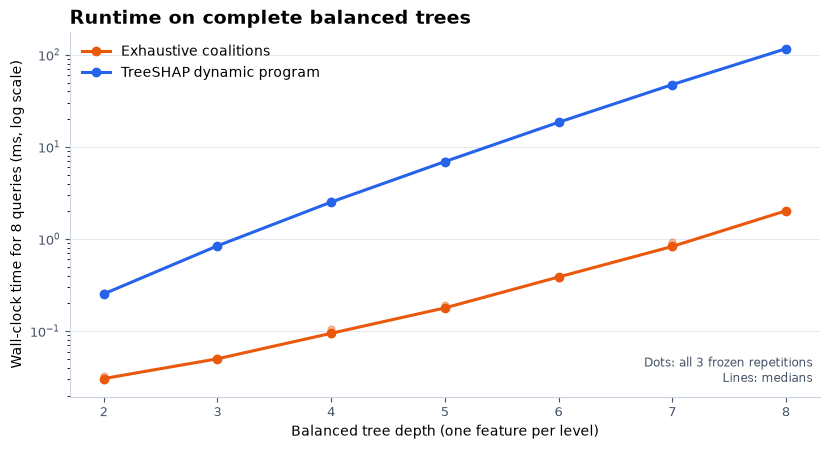

In [36]:
show_figure(
    plots.plot_runtime_dummy_features(diagnostics["timing"]),
    "13_runtime_dummy_features",
)
show_figure(
    plots.plot_runtime_depth(diagnostics["timing"]),
    "14_runtime_depth",
)


### Try It Yourself 2 — explain another recipe and another game

Change any four settings. `row` selects a held-out recipe; `model_key` can use `tree`, `forest`, or
`boost`, `clean` or `shuffled`, and seed index 0–2; `game` chooses the missing-feature definition;
`size` changes the empirical background when the interventional game is selected.

Before running, predict what should remain invariant. The full model prediction is fixed for a
chosen model and row. The base and individual contributions can move with the game or background.
This cell deliberately reuses audit rows after evaluation and is exploratory only. Choices made here
after seeing audit results cannot support a new confirmatory audit claim.


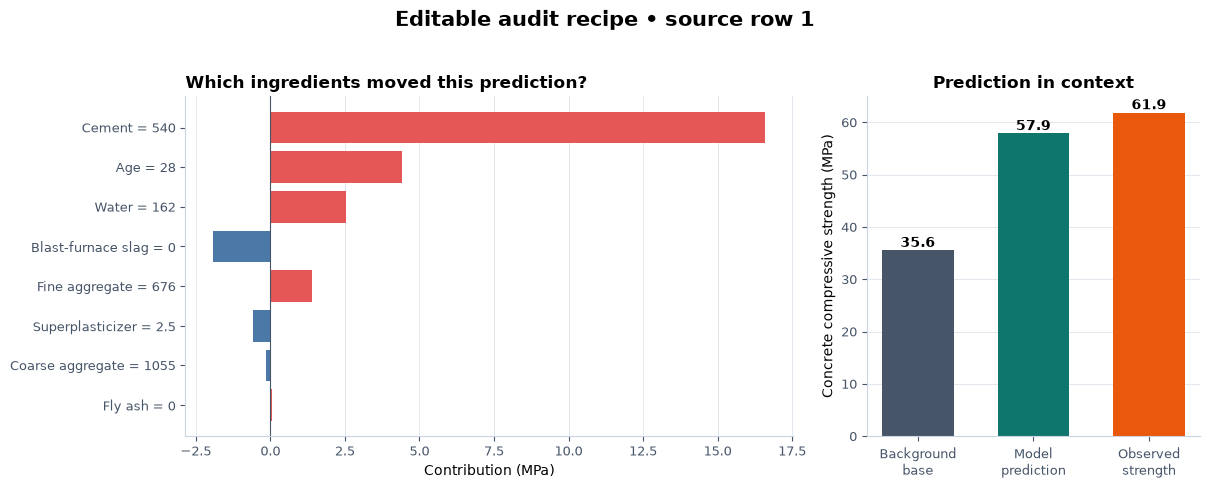

In [37]:
row = 0
model_key = "forest_clean_0"
game = "interventional"  # choose "interventional" or "path"
size = 64                 # used only by the interventional game

real_play = native_play(
    fitted, train, audit,
    model_key=model_key, row=row, size=size, game=game,
)
show_figure(plots.plot_real_recipe_play(real_play, FEATURE_NAMES), "16_real_recipe_play")


## Interpreting the study

Use the figures in this order.

1. **Predictive control:** compare clean fits with the training-mean baseline and shuffled-target
   fits on held-out recipe groups.
2. **Numerical validity:** require exhaustive full-vector parity. Then inspect the raw library
   failure and the separately labeled threshold-compatible parity; do not collapse them into one
   pass flag.
3. **Local explanation:** read the waterfall as a decomposition relative to its displayed base.
4. **Across rows:** inspect the heatmap for recurring direction and heterogeneity rather than
   reducing every feature to one mean bar.
5. **Definition sensitivity:** compare path and interventional games, then alternate backgrounds.
6. **Usefulness control:** compare fixed-order deletion curves with all random orders and the
   efficient non-Shapley Saabas baseline.

A large positive contribution for cement, for example, means that this fitted model predicts more
strength for this recipe relative to the specified missing-feature reference. It does not identify
the effect of adding cement while holding a physically feasible recipe constant. Ingredient
quantities co-vary, duplicated recipes have conflicting outcomes, and laboratory identity is
unavailable.


## Limitations

- **The game is a modeling choice.** Path-dependent absence follows fitted tree structure and cover.
  Empirical intervention follows a finite donor background. Neither is automatically the population
  conditional game.
- **Hybrids may be off-support.** Copying present coordinates from one recipe and missing
  coordinates from another can produce unrealistic mixtures.
- **The split unit is a recipe group, not a laboratory.** Identical seven-ingredient recipes remain
  together, but unobserved laboratory or batch dependence can cross splits.
- **Prediction is not causation.** The study explains fixed regressors. It neither estimates
  ingredient interventions nor retrains models after feature removal.
- **Background stability is finite.** The alternate-background panel probes several frozen samples;
  it does not integrate over all reasonable reference populations.
- **Reference agreement has a scope.** Library parity supports this scalar-output scikit-learn path
  under the installed SHAP version. It does not validate every tree package, missing-value
  convention, classifier link, or output transform.
- **Timing is descriptive.** Python overhead, tree shape, batching and hardware affect the measured
  curves.

## Further research and anomaly hunting

Good extensions change one scientific assumption at a time:

- find rows whose largest feature changes sign between path and interventional games, then inspect
  their nearest background recipes;
- repeat the background control with a scientifically motivated reference population and state what
  changed in the estimand;
- locate deletion curves where Saabas beats both Shapley rankings and determine whether the gain
  comes from the tree's fixed split order;
- construct two larger functionally equivalent trees with different structures and quantify
  path-game disagreement;
- profile a compiled or vectorized recurrence and ask where it crosses the exhaustive oracle on a
  separately declared, bounded tree sweep rather than extending the frozen range after seeing it;
- extend the recurrence to explicit missing-value routes or categorical splits, adding exhaustive
  fixtures before fitted-model use.

Do not treat an unexpected attribution as an error until you have identified the game, prediction,
base, row, model and reference population that generated it.


## Reading

- Scott Lundberg, Gabriel Erion & Su-In Lee, [*Consistent Individualized Feature Attribution for
  Tree Ensembles*](https://arxiv.org/abs/1802.03888), especially Section 3 and Algorithms 1–2.
- [SHAP `TreeExplainer`
  documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), for the
  current library's explicit perturbation modes and output choices.
- I-Cheng Yeh, [UCI Concrete Compressive
  Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), for the source
  data and measurement description.

The frozen source-row membership, hashes, model settings, background ordering and evaluation
decisions are recorded in `protocol.md`, `protocol_freeze.json`, `data_manifest.json` and
`author_reference.json` beside this lesson.


In [38]:
# Persist the complete visible run. All scientific computations occurred above.
summary = persist_completed(
    NATIVE_DIR, fitted, prepared, evaluated, diagnostics, reference, default_play
)
write_notebook_summary(OUTPUT_ROOT, NATIVE_DIR, summary)
print("Saved notebook-native payloads to", NATIVE_DIR)


Saved notebook-native payloads to /home/bitwise/.cache/arena_extended/treeshap/learner-v7/figures/native
